# From Zero: What Was Added to the DeFi Long--Short Framework, and Why

**Who this notebook is for.** A first-year student who knows differentiation,
integration, and what a random variable is. Nothing else is assumed. Every symbol is
defined the first time it is used, every formula is derived rather than quoted, and every
claim is checked numerically in the cell that follows it.

**What this notebook is about.** The repository already contained a paper that prices a
*leveraged long--short position on a DeFi lending protocol*. A batch of work was then added
on top of it. This notebook walks through **each addition, one at a time**, in this order:

| # | Addition | New file | Section here |
|---|---|---|---|
| 0 | Foundations you need before anything else | --- | Parts I--III |
| 1 | The **evaluation map**: separating what the model computes from what you decide | (paper §2.2) | Part IV |
| 2 | A **protocol data layer**: real Aave v3 hourly history for 12 reserves | `aave_hourly.py` | Part V |
| 3 | **Carry as an effective drift** --- interest folded in with no new mathematics | `carry.py` | Part VI |
| 4 | A **pre-registered screen** and a 37-pair cross-section: carry is inert | `screen.py` | Part VII |
| 5 | The **depeg overlay** --- a stress test that costs nothing | `carry.py` | Part VIII |
| 6 | The **rate curve and utilization model** --- why the old CIR fits were wrong | `rate_curve.py` | Part IX |
| 7 | **Liquidation recovery** $R_\tau$ --- what the borrower actually keeps | `recovery.py` | Part X |
| 8 | **Regime-switching carry** --- the $3\times3$ barrier system becomes $6\times6$ | `regime_switching.py` | Part XI |
| 9 | The **barbell** --- buying the two convexities the levered book sells | `barbell.py` | Part XII |
| 10 | **Sizing on the map**: the break-even drift, and a realised backtest of whether leverage paid | (paper §8) | Part XIII |

Parts I--III are the background. If you already know what a health factor, a Kou process
and a Laplace transform are, skim them and start at Part IV.

**How to read the code.** Every code cell is short and does one thing. Nothing is hidden in
helper functions defined in this notebook: the real work lives in the `optimal_long_short`
package, and each cell says which module it is calling.

---
## Part 0. Setup

Run this once. It loads the calibrated parameters and the Aave data that the rest of the
notebook uses. Everything after this point runs in a few seconds.

In [1]:
import json
import math
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Make the repository importable when the notebook is run from notebooks/.
ROOT = Path.cwd()
if not (ROOT / "optimal_long_short").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from optimal_long_short.aave_hourly import DATA_DIR, published_curve
from optimal_long_short.job_runners.common import load_calibrated_params
from optimal_long_short.screen import ScreenConfig, load_panel

plt.rcParams.update({"figure.figsize": (9, 4), "figure.dpi": 110,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
pd.set_option("display.width", 130, "display.max_columns", 40,
              "display.float_format", lambda v: f"{v:,.4f}")

# --- the calibrated model -------------------------------------------------
# params : the fitted Kou parameters for the WBTC (asset 1) / WETH (asset 2) pair
# market : the Aave contract terms for that position
# The merged paper's benchmark: ECF shape parameters with the window's sample drifts
# (price growth plus Aave rates); see Part XIII.3 for why the drift is kept outside the fit.
params, market = load_calibrated_params(ROOT / "results/params_WBTC_WETH_benchmark.json")

# --- the protocol data ----------------------------------------------------
configs = pd.read_csv(DATA_DIR / "reserve_configs_v3_eth.csv", index_col=0)
panel = load_panel()                 # hourly history, keyed by reserve symbol
CFG = ScreenConfig()                 # the pre-registered window and universe size

B = market["b"]                      # liquidation threshold of the collateral
T = 1.0 / 12.0                       # one-month horizon, in years

print(f"Kou parameters   : mu1={params.mu1:.4f}  mu2={params.mu2:.4f}  "
      f"sigma1={params.sigma1:.4f}  sigma2={params.sigma2:.4f}  rho={params.rho:.4f}")
print(f"Contract terms   : b={B}  LTV_max={market['ltv_max']}  "
      f"liquidation bonus={market['liq_bonus']}")
print(f"Reserves on file : {len(panel)}  ({', '.join(sorted(panel))})")
print(f"Window           : {CFG.window_start.date()} to {CFG.window_end.date()}")

Kou parameters   : mu1=-0.3137  mu2=-0.4168  sigma1=0.2642  sigma2=0.3282  rho=0.8475
Contract terms   : b=0.78  LTV_max=0.73  liquidation bonus=0.05
Reserves on file : 12  (DAI, GHO, LINK, USDC, USDT, USDe, WBTC, WETH, cbBTC, tBTC, weETH, wstETH)
Window           : 2026-03-17 to 2026-08-04


---
# Part I. The position, from zero

## I.1 What a lending protocol lets you do

Aave is a pool of deposits. You can do exactly two things with it:

* **Supply** an asset. You hand over tokens, the pool credits you, and you earn a *supply
  rate* $r_s$ while your tokens sit there being lent out to other people.
* **Borrow** an asset, *provided you have supplied something first as collateral*. You pay a
  *borrow rate* $r_b$ on what you owe.

Because you must post collateral before you borrow, the protocol is *over-collateralised*:
what you put in is worth more than what you take out. That is what makes the loan safe for
the pool without knowing who you are.

## I.2 Building a leveraged long--short position

Suppose you think asset 1 will outperform asset 2. Concretely: you think WBTC will do better
than WETH. Here is how you express that view on Aave.

1. Supply $n_1$ units of asset 1 as collateral. Its price at time $t$ is $S_{1,t}$, so the
   collateral is worth $V_{1,t} = n_1 S_{1,t}$.
2. Borrow $n_2$ units of asset 2. You now *owe* $V_{2,t} = n_2 S_{2,t}$.
3. Sell the borrowed asset 2 and buy more of asset 1 with the proceeds.

You are now **long asset 1** (you own $n_1$ units) and **short asset 2** (you owe $n_2$ units
you no longer hold). If $S_1$ rises relative to $S_2$, your collateral grows faster than your
debt and you make money. If it falls, you lose --- and the protocol has a mechanism to stop
you losing *its* money.

**Every symbol so far**

| Symbol | Meaning | Units |
|---|---|---|
| $S_{i,t}$ | price of asset $i$ at time $t$ | USD per token |
| $n_i$ | number of tokens of asset $i$ in the position | tokens |
| $V_{i,t} = n_i S_{i,t}$ | value of leg $i$ | USD |
| $t$ | time | years |

## I.3 The health factor

The protocol needs one number that says "is this loan still safe?". It is the **health
factor**

$$\boxed{\;H_t \;=\; \frac{b\,V_{1,t}}{V_{2,t}} \;=\; \frac{b\,n_1 S_{1,t}}{n_2 S_{2,t}}\;}$$

Read it as a fraction: **numerator = what the protocol can actually count on**, **denominator
= what you owe**.

* $b \in (0,1)$ is the **liquidation threshold**, a haircut the protocol applies to your
  collateral. For WBTC on Aave v3 Ethereum $b = 0.78$: a dollar of WBTC only counts as 78
  cents of backing. The haircut exists because seizing and selling collateral takes time,
  during which the price moves.
* If $H_t \ge 1$ the discounted collateral still covers the debt: you are safe.
* If $H_t < 1$ it does not: **anyone** may liquidate you, repaying part of your debt and
  seizing collateral in exchange, plus a bonus.

Define the **liquidation time**

$$\tau \;=\; \inf\{\,t \ge 0 \;:\; H_t < 1\,\},$$

the first moment the health factor dips below one. "$\inf$" is just "the earliest such $t$";
if it never happens, $\tau = \infty$.

## I.4 Take logarithms --- and the problem collapses to one dimension

$H_t$ is a ratio of products, which is awkward. Logarithms turn products into sums, so set

$$h_t \;=\; \log H_t.$$

Because $\log(xy) = \log x + \log y$ and $\log(x/y) = \log x - \log y$,

$$h_t \;=\; \log b + \log n_1 + \log S_{1,t} - \log n_2 - \log S_{2,t}.$$

Now write the log-price *change* of each asset since time $0$ as

$$X_{i,t} \;=\; \log\frac{S_{i,t}}{S_{i,0}}, \qquad\text{so}\qquad S_{i,t} = S_{i,0}e^{X_{i,t}},
\qquad X_{i,0}=0 .$$

$X_{i,t}$ is the **cumulative log-return** of asset $i$. Substituting $S_{i,t}=S_{i,0}e^{X_{i,t}}$:

$$h_t = \underbrace{\log\frac{b\,n_1S_{1,0}}{n_2S_{2,0}}}_{\textstyle h_0}
      \;+\; \underbrace{X_{1,t}-X_{2,t}}_{\textstyle Z_t}.$$

So

$$\boxed{\;h_t \;=\; h_0 + Z_t, \qquad Z_t := X_{1,t}-X_{2,t}.\;}$$

This is the single most important line in the whole framework. Two assets, two prices, two
sources of randomness --- and yet the *only* thing that decides whether you are liquidated is
one scalar process $Z_t$, the **log price ratio**, starting at $Z_0=0$, and one number $h_0$,
the **initial log buffer**. The liquidation time becomes

$$\tau = \inf\{t\ge 0:\ h_0 + Z_t < 0\} = \inf\{t \ge 0:\ Z_t < -h_0\}.$$

In words: **$\tau$ is the first time a one-dimensional random path falls a distance $h_0$
below where it started.** That is a *first-passage problem*, and everything in this
repository is machinery for solving it fast and exactly.

## I.5 Leverage: what $h_0$ costs you

Your own money in the trade is the **equity** $E_0 = V_{1,0}-V_{2,0}$: collateral minus debt.
Gross **leverage** is exposure over equity,

$$L_0 \;=\; \frac{V_{1,0}}{V_{1,0}-V_{2,0}}.$$

Let us express it in terms of $h_0$ alone. From $H_0 = bV_{1,0}/V_{2,0}$ we get
$V_{2,0} = bV_{1,0}/H_0$, so

$$L_0 \;=\; \frac{V_{1,0}}{V_{1,0} - bV_{1,0}/H_0}
      \;=\; \frac{1}{1 - b/H_0}
      \;=\; \boxed{\;\frac{H_0}{H_0-b}\;},\qquad H_0=e^{h_0}.$$

Sanity checks on the formula:

* $H_0 \to \infty$ (huge buffer, no borrowing) gives $L_0 \to 1$: unlevered.
* $H_0 \downarrow b$ gives $L_0 \to \infty$: you have borrowed right up to the point where the
  haircut collateral exactly equals the debt.
* $H_0 = b$ is not allowed, so $h_0 > \log b$ always. Since $b<1$, $\log b<0$.

There is a second, tighter constraint. Aave will not *let you open* a position at
$H_0$ arbitrarily close to $b$: origination uses a stricter **loan-to-value** cap
$\mathrm{LTV}_{\max} < b$. Requiring $V_{2,0} \le \mathrm{LTV}_{\max}V_{1,0}$ gives

$$H_0 = \frac{bV_{1,0}}{V_{2,0}} \;\ge\; \frac{b}{\mathrm{LTV}_{\max}},
\qquad\text{i.e.}\qquad h_0 \;\ge\; h_0^{\min} := \log\frac{b}{\mathrm{LTV}_{\max}} \;>\;0 .$$

For WBTC ($b=0.78$, $\mathrm{LTV}_{\max}=0.73$) that is $h_0^{\min}=\log(0.78/0.73)=0.0662$,
i.e. $H_0 \ge 1.068$ and $L_0 \le 3.7$.

**The trade-off in one line:** small $h_0$ = high leverage = big payoff *and* a barrier close
enough to hit. The entire model exists to quantify that sentence.

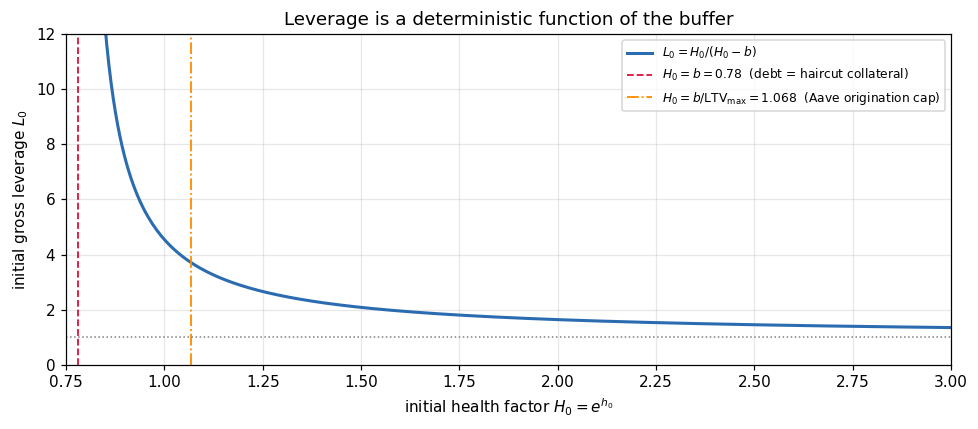

h0_min = log(b / LTV_max) = log(0.78/0.73) = 0.0662
  -> H0_min = 1.0685,  L0_max = 3.704x


In [2]:
# --- Part I: leverage and the feasible set -------------------------------
ltv_max = market["ltv_max"]
h0_min = math.log(B / ltv_max)

H0 = np.linspace(B + 1e-3, 3.0, 400)
L0 = H0 / (H0 - B)

fig, ax = plt.subplots()
ax.plot(H0, L0, lw=2, color="#2b6cb0", label=r"$L_0=H_0/(H_0-b)$")
ax.axvline(B, color="crimson", ls="--", lw=1.2, label=fr"$H_0=b={B}$  (debt = haircut collateral)")
ax.axvline(math.exp(h0_min), color="darkorange", ls="-.", lw=1.2,
           label=fr"$H_0=b/\mathrm{{LTV}}_{{\max}}={math.exp(h0_min):.3f}$  (Aave origination cap)")
ax.axhline(1.0, color="grey", ls=":", lw=1)
ax.set_xlabel(r"initial health factor $H_0=e^{h_0}$")
ax.set_ylabel(r"initial gross leverage $L_0$")
ax.set_ylim(0, 12); ax.set_xlim(0.75, 3.0)
ax.set_title("Leverage is a deterministic function of the buffer")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"h0_min = log(b / LTV_max) = log({B}/{ltv_max}) = {h0_min:.4f}")
print(f"  -> H0_min = {math.exp(h0_min):.4f},  L0_max = "
      f"{math.exp(h0_min)/(math.exp(h0_min)-B):.3f}x")

---
# Part II. The randomness, from zero: building the Kou process

We need a model for $X_{i,t}$, the cumulative log-return. We build it in four steps, each one
adding exactly one feature.

## II.1 Step 1 --- a random walk

Chop $[0,t]$ into $n$ small intervals of length $\Delta = t/n$. In each interval the log-price
moves by an independent random amount $\varepsilon_k$ with mean $m\Delta$ and variance
$s^2\Delta$. Then

$$X_t^{(n)} \;=\; \sum_{k=1}^{n}\varepsilon_k, \qquad
\mathbb E[X_t^{(n)}] = m t, \qquad \operatorname{Var}(X_t^{(n)}) = s^2 t .$$

Note what the two scalings do: the **mean grows like $t$** and the **variance grows like $t$**,
so the *standard deviation* grows like $\sqrt t$. Over a short horizon randomness ($\sqrt t$)
dominates drift ($t$); over a long horizon drift wins. This single fact will decide, in Part
VI, whether interest rates matter at all.

## II.2 Step 2 --- let $n\to\infty$: Brownian motion

By the Central Limit Theorem the sum of many small independent pieces becomes Gaussian, and
the limit is **Brownian motion** $B_t$: the unique process with $B_0=0$, independent
increments, and $B_t-B_s \sim \mathcal N(0,\,t-s)$, with continuous paths. Our first model is

$$X_t \;=\; \mu^X t + \sigma B_t,$$

where $\mu^X$ is the **drift** (per year) and $\sigma$ the **volatility** (per $\sqrt{\text{year}}$).

## II.3 Step 3 --- crypto jumps, so add jumps

Brownian paths are continuous: to fall $10\%$ they must pass through $-1\%$, $-2\%$, and so on.
Crypto prices do not behave like that; they gap. So add a **compound Poisson** term.

*The Poisson counter.* Let $N_t$ count jumps up to time $t$, with **intensity** $\lambda$ (jumps
per year). It satisfies

$$\mathbb P(N_t = k) \;=\; e^{-\lambda t}\frac{(\lambda t)^k}{k!}, \qquad \mathbb E[N_t]=\lambda t .$$

*The jump sizes.* Each jump $n$ has a random size $J_n$, all independent of each other, of $N$,
and of $B$. Our model becomes

$$\boxed{\;X_t \;=\; \mu^X t \;+\; \sigma B_t \;+\; \sum_{n=1}^{N_t} J_n\;}$$

This is a **jump-diffusion**.

## II.4 Step 4 --- Kou's double-exponential jump law

Kou (2002) makes a specific, deliberate choice for the law of $J$:

$$J \;=\;
\begin{cases}
+\xi_+, & \text{with probability } p, \qquad \xi_+ \sim \mathrm{Exp}(\text{mean }\eta_+),\\[2pt]
-\xi_-, & \text{with probability } 1-p, \qquad \xi_- \sim \mathrm{Exp}(\text{mean }\eta_-).
\end{cases}$$

So a jump is up with probability $p$ and down with probability $1-p$; its magnitude is
exponential with mean $\eta_+$ upward, $\eta_-$ downward. The density is

$$f_J(x) \;=\; \frac{p}{\eta_+}e^{-x/\eta_+}\mathbf 1_{\{x>0\}}
\;+\; \frac{1-p}{\eta_-}e^{-|x|/\eta_-}\mathbf 1_{\{x<0\}} .$$

**Why exponential and not, say, Gaussian?** Because of the *memorylessness* property of the
exponential distribution:

$$\mathbb P(\xi > a+x \mid \xi > a) = \mathbb P(\xi > x) \quad\text{for all } a,x>0 .$$

This is the property that makes first-passage problems solvable in closed form. When a
downward jump carries the process across the liquidation barrier, memorylessness says the
*overshoot* below the barrier is again exponential with the same mean $\eta_-$, independently
of how the barrier was reached. That single fact is why the Laplace transforms in Part III
reduce to a small linear system instead of an integral equation. Every parameter in the
model is there to be tractable *and* to fit the data.

## II.5 The compensator $\chi$: making the drift mean what you want

Here is a subtlety that trips everyone up the first time. We would like the parameter we
calibrate to have a clean economic meaning:

$$\mathbb E\big[e^{X_t}\big] \;=\; e^{\mu t}
\qquad\Longleftrightarrow\qquad
\mathbb E\!\left[\frac{S_t}{S_0}\right] = e^{\mu t},$$

so $\mu$ is the **expected price growth rate**. But the drift that appears *inside* the
process is $\mu^X$, and it is not the same number. Let us compute the relationship.

The three pieces $\mu^X t$, $\sigma B_t$ and $\sum_{n\le N_t}J_n$ are independent, so the
expectation of the product factorises:

$$\mathbb E\big[e^{X_t}\big]
= e^{\mu^X t}\cdot \mathbb E\big[e^{\sigma B_t}\big]\cdot
  \mathbb E\Big[e^{\sum_{n\le N_t}J_n}\Big].$$

*Second factor.* For $Y\sim\mathcal N(0,v)$ we have $\mathbb E[e^{Y}]=e^{v/2}$ (complete the
square in the Gaussian integral). Here $\sigma B_t \sim \mathcal N(0,\sigma^2 t)$, so

$$\mathbb E\big[e^{\sigma B_t}\big] = e^{\sigma^2 t/2}.$$

*Third factor.* Condition on the number of jumps and use independence:

$$\mathbb E\Big[e^{\sum_{n\le N_t}J_n}\Big]
= \sum_{k=0}^{\infty}\mathbb P(N_t=k)\,\big(\mathbb E[e^{J}]\big)^{k}
= \sum_{k=0}^{\infty} e^{-\lambda t}\frac{(\lambda t)^k}{k!}\,M^{k}
= e^{-\lambda t}e^{\lambda t M}
= e^{\lambda t (M-1)},$$

where $M := \mathbb E[e^{J}]$ and we used the exponential series
$\sum_k z^k/k! = e^{z}$ with $z=\lambda t M$.

*Computing $M$.* Split on the sign of the jump. For $\xi_+\sim\mathrm{Exp}(\text{mean }\eta_+)$,

$$\mathbb E\big[e^{\xi_+}\big]=\int_0^\infty e^{x}\frac{1}{\eta_+}e^{-x/\eta_+}\,dx
=\frac{1}{\eta_+}\int_0^\infty e^{-x(1/\eta_+-1)}dx
=\frac{1/\eta_+}{1/\eta_+-1}=\frac{1}{1-\eta_+},$$

which is **finite only if $\eta_+<1$** --- the integral diverges otherwise. Similarly
$\mathbb E[e^{-\xi_-}]=1/(1+\eta_-)$, always finite. Hence

$$\boxed{\;M \;=\; \frac{p}{1-\eta_+} + \frac{1-p}{1+\eta_-}\;},
\qquad
\boxed{\;\chi \;:=\; M-1 \;=\; \mathbb E\big[e^{J}-1\big]\;}$$

$\chi$ is the **jump compensator**: the average *proportional* price move caused by one jump.

*Putting it together.*

$$\mathbb E\big[e^{X_t}\big] = \exp\!\Big(t\big[\mu^X + \tfrac12\sigma^2 + \lambda\chi\big]\Big)
\;\stackrel{!}{=}\; e^{\mu t}
\qquad\Longrightarrow\qquad
\boxed{\;\mu^X \;=\; \mu - \tfrac12\sigma^2 - \lambda\chi\;}$$

Read it as: to make the *price* grow at rate $\mu$ on average, the *log-price* must drift
more slowly, because both volatility ($\tfrac12\sigma^2$, Jensen's inequality) and jumps
($\lambda\chi$) push $\mathbb E[e^{X}]$ up on their own. This is exactly what
`KouParams.__post_init__` computes for you, and why you supply $\mu$ but the machinery uses
$\mu^X$.

## II.6 The Lévy exponent: one function that encodes the whole law

For any process with independent, stationary increments there is a single function $\Psi$
such that

$$\mathbb E\big[e^{i u X_t}\big] \;=\; e^{t\,\Psi(u)} \qquad\text{for all } t,u .$$

$\Psi$ is the **Lévy exponent** (or characteristic exponent). *Why it exists*: independence
of increments makes $g(t) := \mathbb E[e^{iuX_t}]$ multiplicative, $g(t+s)=g(t)g(s)$, and the
only continuous solutions of that functional equation are exponentials. Repeating the
calculation of §II.5 with $1$ replaced by $iu$:

$$\Psi(u) \;=\; i u\,\mu^X \;-\; \tfrac12\sigma^2u^2 \;+\; \lambda\big(\mathbb E[e^{iuJ}]-1\big),
\qquad
\mathbb E[e^{iuJ}] = \frac{p}{1-iu\eta_+}+\frac{1-p}{1+iu\eta_-}.$$

Two things to notice, because both matter later.

1. **The exponent is a rational function of $u$** --- a ratio of polynomials, with poles at
   $u = -i/\eta_+$ and $u = +i/\eta_-$ (four in total for the pair of assets). Everything
   "polynomial" that happens in Parts X and XI comes from clearing these denominators.
2. **The drift enters linearly**, as the single term $iu\mu^X$. Change the drift and you change
   $\Psi$ by a straight line. Part VII is nothing more than that observation applied to
   interest rates.

## II.7 The process that actually matters: $Z = X_1-X_2$

We need the exponent of the *ratio* process. With two correlated Brownian motions
($\operatorname{Corr}(B_1,B_2)=\rho$),

$$\operatorname{Var}(\sigma_1B_{1,t}-\sigma_2B_{2,t})
= \big(\sigma_1^2+\sigma_2^2-2\rho\sigma_1\sigma_2\big)\,t
\;=:\; \sigma_Z^2\,t,$$

using $\operatorname{Var}(A-B)=\operatorname{Var}A+\operatorname{Var}B-2\operatorname{Cov}(A,B)$.
The jumps of $X_1$ and $X_2$ arrive independently, so $Z$ inherits **both** jump components:
upward jumps of $X_1$ and downward jumps of $X_2$ push $Z$ up; the other two push it down. $Z$
therefore has **two upward exponential phases** (rates $1/\eta_{1,+}$ and $1/\eta_{2,-}$) and
**two downward phases** (rates $1/\eta_{1,-}$ and $1/\eta_{2,+}$). Those four rates are the
four poles of §II.6, and the two downward ones --- called $r_{1,-}, r_{2,-}$ in the code --- are
exactly the ones the barrier conditions in Part III will have to handle.

The **correlation is doing enormous work**. At the calibrated $\rho=0.847$, WBTC and WETH move
together most of the time, so the *spread* is far quieter than either leg. That is the whole
economic point of a long--short book.

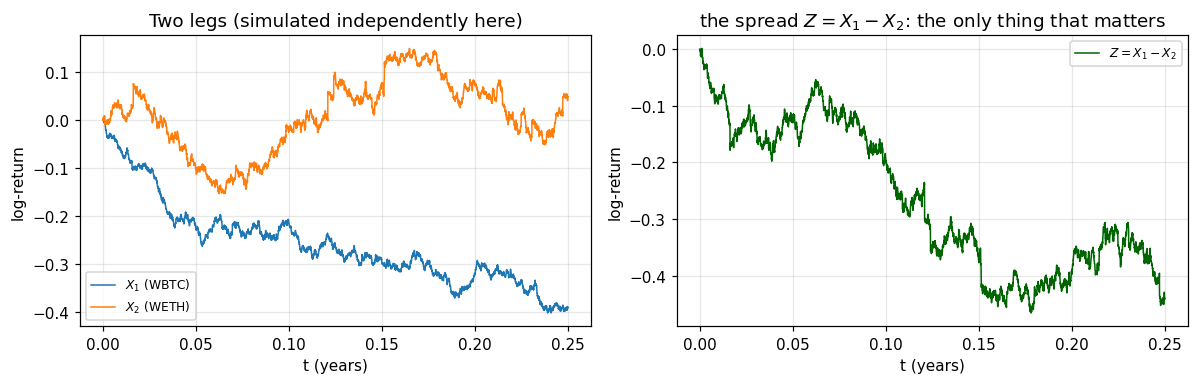

sigma_1 = 0.2642,  sigma_2 = 0.3282,  rho = 0.8475
sigma_Z = sqrt(s1^2 + s2^2 - 2 rho s1 s2) = 0.1748   <-- much smaller than either leg, because rho is high
barrier scale over T=1/12:  sigma_Z*sqrt(T) = 0.0505


In [3]:
# --- Part II: simulate the Kou process we just built ---------------------
def simulate_kou(mu_X, sigma, lam, p, eta_pos, eta_neg, T, n_steps, rng):
    "One path of  X_t = mu_X t + sigma B_t + sum_{n<=N_t} J_n,  built literally as in II.4."
    dt = T / n_steps
    incr = mu_X * dt + sigma * np.sqrt(dt) * rng.standard_normal(n_steps)  # drift + diffusion
    n_jumps = rng.poisson(lam * dt, n_steps)                              # Poisson counter
    for k in np.flatnonzero(n_jumps):
        for _ in range(n_jumps[k]):
            up = rng.random() < p                                          # up with prob. p
            incr[k] += rng.exponential(eta_pos) if up else -rng.exponential(eta_neg)
    return np.concatenate([[0.0], np.cumsum(incr)])

rng = np.random.default_rng(7)
n_steps, T_plot = 4000, 0.25
grid_t = np.linspace(0, T_plot, n_steps + 1)

x1 = simulate_kou(params.muX1, params.sigma1, params.lam1, params.p1,
                  params.eta1_pos, params.eta1_neg, T_plot, n_steps, rng)
x2 = simulate_kou(params.muX2, params.sigma2, params.lam2, params.p2,
                  params.eta2_pos, params.eta2_neg, T_plot, n_steps, rng)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(grid_t, x1, lw=1, label=r"$X_1$ (WBTC)")
axes[0].plot(grid_t, x2, lw=1, label=r"$X_2$ (WETH)")
axes[0].set_title("Two legs (simulated independently here)")
axes[1].plot(grid_t, x1 - x2, lw=1, color="darkgreen", label=r"$Z=X_1-X_2$")
axes[1].set_title(r"the spread $Z=X_1-X_2$: the only thing that matters")
for a in axes:
    a.set_xlabel("t (years)"); a.set_ylabel("log-return"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

sigma_Z = math.sqrt(params.sigma1**2 + params.sigma2**2
                    - 2 * params.rho * params.sigma1 * params.sigma2)
print(f"sigma_1 = {params.sigma1:.4f},  sigma_2 = {params.sigma2:.4f},  rho = {params.rho:.4f}")
print(f"sigma_Z = sqrt(s1^2 + s2^2 - 2 rho s1 s2) = {sigma_Z:.4f}"
      f"   <-- much smaller than either leg, because rho is high")
print(f"barrier scale over T=1/12:  sigma_Z*sqrt(T) = {sigma_Z*math.sqrt(T):.4f}")

In [4]:
# --- Part II: check the compensator identity  E[exp(X_t)] = exp(mu t) ----
# This is the derivation of II.5 verified by brute force.
chi1 = params.p1 / (1 - params.eta1_pos) + (1 - params.p1) / (1 + params.eta1_neg) - 1
print(f"chi_1 = M_1(1) - 1, by hand from II.5      : {chi1:.6f}")
print(f"  average proportional move per jump: {100*chi1:+.4f}%,  at "
      f"lam_1 = {params.lam1:.1f} jumps/yr  ->  lam_1*chi_1 = {params.lam1*chi1:.6f}")
# NB: KouParams.jump_compensator1 stores the FULL drift adjustment 0.5*sigma^2 + lam*chi,
# not chi itself -- so compare against that combination.
print(f"  0.5*sigma_1^2 + lam_1*chi_1                : "
      f"{0.5*params.sigma1**2 + params.lam1*chi1:.6f}")
print(f"  KouParams.jump_compensator1                : {params.jump_compensator1:.6f}")
print(f"muX1 = mu1 - s1^2/2 - lam1*chi1              : "
      f"{params.mu1 - 0.5*params.sigma1**2 - params.lam1*chi1:.6f}")
print(f"muX1 stored by KouParams                     : {params.muX1:.6f}\n")

T_chk, n_paths = 0.25, 200_000
rng = np.random.default_rng(1)
# vectorised one-shot simulation of X_{1,T}: drift + diffusion + a Poisson number of jumps
N = rng.poisson(params.lam1 * T_chk, n_paths)
tot = np.zeros(n_paths)
for k in range(1, N.max() + 1):
    mask = N >= k
    up = rng.random(mask.sum()) < params.p1
    sz = np.where(up, rng.exponential(params.eta1_pos, mask.sum()),
                  -rng.exponential(params.eta1_neg, mask.sum()))
    tot[mask] += sz
XT = params.muX1 * T_chk + params.sigma1 * np.sqrt(T_chk) * rng.standard_normal(n_paths) + tot
print(f"Monte Carlo  E[exp(X_1,T)] = {np.exp(XT).mean():.5f}   (n = {n_paths:,})")
print(f"Theory       exp(mu_1 T)   = {math.exp(params.mu1 * T_chk):.5f}")

chi_1 = M_1(1) - 1, by hand from II.5      : 0.002350
  average proportional move per jump: +0.2350%,  at lam_1 = 358.3 jumps/yr  ->  lam_1*chi_1 = 0.842092
  0.5*sigma_1^2 + lam_1*chi_1                : 0.876994
  KouParams.jump_compensator1                : 0.876994
muX1 = mu1 - s1^2/2 - lam1*chi1              : -1.190731
muX1 stored by KouParams                     : -1.190731



Monte Carlo  E[exp(X_1,T)] = 0.92432   (n = 200,000)
Theory       exp(mu_1 T)   = 0.92456


---
# Part III. What the base paper already computed

Before looking at what was *added*, you need to know what was already there.

## III.1 The payoff, and the killed-payoff convention

You hold the position for a fixed horizon $T$ (here one month, $T=1/12$ years). If you survive
to $T$, you close: sell the collateral, repay the debt, keep the difference,

$$\Pi_T^{\text{survive}} \;=\; n_1S_{1,T}-n_2S_{2,T}.$$

If you are liquidated first, the base paper sets the payoff to zero. Formally

$$\boxed{\;\Pi_T \;=\; \big(n_1S_{1,T}-n_2S_{2,T}\big)\,\mathbf 1_{\{\tau>T\}}\;}$$

The symbol $\mathbf 1_{\{A\}}$ is the **indicator**: $1$ if the event $A$ happens, $0$
otherwise. A payoff multiplied by an indicator of "no barrier hit" is called a **killed**
payoff --- the barrier "kills" the path.

Setting the liquidated payoff to zero is a *conservative convention*, not a claim that you
literally lose everything. **Fixing it is addition #7 (Part X).**

## III.2 Normalisation: work per dollar of equity

Payoffs should be comparable across leverage levels, so everything is expressed **per unit of
initial equity**: set $n_1S_{1,0}-n_2S_{2,0}=1$. Combined with $H_0 = bn_1S_{1,0}/(n_2S_{2,0})$
these two equations give, after a line of algebra,

$$n_2S_{2,0} \;=\; \frac{b}{e^{h_0}-b}, \qquad n_1S_{1,0} \;=\; \frac{e^{h_0}}{e^{h_0}-b} \;=\; L_0 .$$

*Derivation.* Write $A=n_1S_{1,0}$, $D=n_2S_{2,0}$. Then $A-D=1$ and $bA/D=H_0=e^{h_0}$, so
$A = e^{h_0}D/b$. Substituting: $e^{h_0}D/b - D = 1 \Rightarrow D(e^{h_0}-b)=b \Rightarrow
D = b/(e^{h_0}-b)$. $\square$

So the debt per dollar of equity **blows up as the buffer shrinks** --- which is just leverage
again, and it is the reason recovery in Part X scales the way it does.

## III.3 What we want: survival and killed moments

Two families of numbers describe the position completely enough for any decision:

* the **survival probability** $p_{\mathrm{surv}}(T,h_0) = \mathbb P(\tau>T)$, and its
  complement the **liquidation probability** $p_{\mathrm{liq}}=1-p_{\mathrm{surv}}$;
* the **killed moments** $M_k(T,h_0) = \mathbb E[\Pi_T^k]$ for $k=1,2,3,\dots$

From $M_1,M_2$ you get the variance; with $M_3,M_4$ you get skewness and kurtosis. Dividing by
$p_{\mathrm{surv}}$ turns them into **conditional** moments --- the distribution *given that you
were not liquidated*, which is what a trader who survived actually experiences.

There is a hard limit on how many moments exist. $\Pi_T^k$ contains a term $(n_2S_{2,T})^k \propto
e^{kX_{2,T}}$, and by §II.5 that expectation is finite only when $k\eta_{2,+}<1$. So

$$\boxed{\;k \;<\; 1/\eta_{2,+}\;}$$

At the calibrated $\eta_{2,+}=0.01126$ this permits $k$ up to $88$. Tails that heavy in the
*short* leg are what make short positions dangerous, and the model is explicit about it.

## III.4 Laplace transforms, from zero --- and why we need them

We cannot compute $\mathbb P(\tau > T)$ directly, because $\tau$ depends on the whole path. The
trick is to compute a *transform* of it and then invert numerically.

**Definition.** For a function $f$ defined on $t\ge 0$, its **Laplace transform** is

$$\widehat f(q) \;=\; \int_0^{\infty} e^{-qt} f(t)\,dt,$$

a function of a new variable $q$ (which we allow to be complex).

**Why it helps.** Two properties, both provable in a line by integration by parts:

$$\widehat{f'}(q) = q\widehat f(q) - f(0), \qquad
\widehat{(f*g)}(q) = \widehat f(q)\,\widehat g(q),$$

where $(f*g)(t)=\int_0^tf(s)g(t-s)ds$ is convolution. **Differentiation becomes multiplication
by $q$.** A differential equation in $t$ therefore becomes an *algebraic* equation in $q$ ---
and algebra we can solve exactly. Then we numerically undo the transform.

**Undoing it.** The inversion integral runs along a vertical line in the complex plane,

$$f(t) \;=\; \frac{1}{2\pi i}\int_{c-i\infty}^{c+i\infty} e^{qt}\widehat f(q)\,dq .$$

Evaluating that naively is hopeless: $e^{qt}$ oscillates wildly. **Talbot's method** deforms
the contour into the left half-plane, where $e^{qt}$ *decays* instead, turning the integral
into a rapidly convergent finite sum. `optimal_long_short.inversion.TalbotInverter(M=32)` uses
$M=32$ evaluation points and reaches near machine precision. This is why the whole framework
is roughly $440\times$ faster than Monte Carlo.

## III.5 The $3\times3$ barrier system, in words

Here is the shape of the argument that produces the survival probability. You do not need
every detail to follow the additions, but you do need the *shape*, because Part XI changes it.

1. Define $u(x) = $ the transformed quantity we want, as a function of the *starting distance*
   $x$ from the barrier.
2. The process is a jump-diffusion, so $u$ satisfies a **partial integro-differential
   equation** $(q-\mathcal L)\widehat u = G$, where $\mathcal L$ is the generator of $Z$ (a
   second derivative for the diffusion plus an integral against the jump density) and $G$ comes
   from the payoff.
3. Because the jump density is a mixture of exponentials, applying $\mathcal L$ to
   $e^{\gamma x}$ returns $\psi(\gamma)e^{\gamma x}$ with $\psi$ *rational*. So the homogeneous
   solutions are exponentials $e^{\gamma x}$ whose exponents solve

   $$\psi(\gamma)=q .$$

   Clearing the four denominators of §II.6 turns this into a **degree-6 polynomial**; three of
   its roots have negative real part, and only those give solutions that stay bounded.
4. Three unknown coefficients therefore need **three boundary conditions**:
   * **absorption** --- the value is $0$ at the barrier (you are liquidated, the killed payoff
     is zero);
   * **two phase-cancellation conditions**, one for each downward exponential phase
     $r_{1,-},r_{2,-}$ of §II.7. These say that the solution, extended by zero below the
     barrier, generates no spurious residual through the jump integral.
5. Solve the resulting $3\times3$ linear system, add the particular solution, invert the
   Laplace transform numerically. Done.

**Remember the count: degree-6 characteristic polynomial, 3 decaying roots, $3\times3$ system.**
Part XI doubles all three.

In [5]:
# --- Part III: the base outputs, on a grid of buffers ---------------------
from optimal_long_short.risk_report import h0_liquidation_moment_report

h0_grid = np.array([h0_min, 0.10, 0.15, 0.25, 0.50, 1.00, 2.00])
base_rows = h0_liquidation_moment_report(params, h0_grid, b=B, T=T, max_moment_order=4)
base = pd.DataFrame(base_rows)

show = ["h0", "H0", "initial_leverage", "p_surv", "p_liq",
        "conditional_mean", "conditional_variance"]
print(f"Base framework, T = {T:.4f} yr, b = {B}\n")
print(base[show].to_string(index=False))
print(f"\nMaximum admissible moment order: k < 1/eta_2+ = {1/params.eta2_pos:.1f}")

Base framework, T = 0.0833 yr, b = 0.78



    h0     H0  initial_leverage  p_surv  p_liq  conditional_mean  conditional_variance
0.0662 1.0685            3.7037  0.5830 0.4170            1.1469                0.0390
0.1000 1.1052            3.3987  0.7545 0.2455            1.0840                0.0367
0.1500 1.1618            3.0428  0.9029 0.0971            1.0291                0.0344
0.2500 1.2840            2.5475  0.9906 0.0094            0.9914                0.0282
0.5000 1.6487            1.8979  1.0000 0.0000            0.9817                0.0149
1.0000 2.7183            1.4024  1.0000 0.0000            0.9775                0.0085
2.0000 7.3891            1.1180  1.0000 0.0000            0.9752                0.0068

Maximum admissible moment order: k < 1/eta_2+ = 88.8


---
# Part IV. Addition #1 --- the evaluation map

**What changed.** A paragraph (§2.2 of `latex/optimal_long_short_merged.tex`) that adds no
formula but reorganises the claim of the paper. It is worth understanding first, because the
final addition (Part XIII) is the reason it was written.

## IV.1 Two different objects

Almost every portfolio paper mixes together two things:

1. **A calculation.** Given a position, what is the probability of liquidation? What is the
   mean and variance of the payoff?
2. **A decision.** Given those numbers, what position *should* you take?

Step 1 depends only on the model and the data. Step 2 depends on *preferences* --- how much
risk you are willing to bear --- which are not in the data at all.

The addition names step 1 and separates it. The **health-buffer evaluation map** is the
function

$$h_0 \;\longmapsto\;
\Big(
p_{\mathrm{liq}}(T,h_0),\;
M_1,\dots,M_K,\;
\frac{M_1}{p_{\mathrm{surv}}},\dots,\frac{M_K}{p_{\mathrm{surv}}}
\Big),
\qquad M_k = \mathbb E[\Pi_T^k].$$

You give it a buffer; it returns everything measurable about the resulting position. **No
preference parameter appears anywhere in it.**

## IV.2 The decision layer, kept separate

A decision rule is then applied *afterwards*. The paper's example is the penalised
mean--variance objective on **unconditional** terminal wealth $W_T$ (Part X adds the recovery
term to $\Pi_T$):

$$\Phi(h_0) \;=\; \underbrace{\mathbb E[W_T]}_{\text{reward}}
\;-\; \underbrace{\frac{\alpha}{2}\operatorname{Var}(W_T)}_{\text{risk aversion}}
\;-\; \underbrace{\delta\,p_{\mathrm{liq}}}_{\text{dislike of being liquidated}},$$

with two free knobs:

* $\alpha \ge 0$, the **risk-aversion** coefficient. The factor $\tfrac12$ is conventional; it
  comes from the second-order Taylor expansion of a utility function,
  $\mathbb E[u(W)]\approx u(\mathbb E W)+\tfrac12u''(\mathbb E W)\operatorname{Var}(W)$, with
  $\alpha=-u''/u'$.
* $\delta \ge 0$, a direct **penalty per unit of liquidation probability** --- capturing costs
  (gas, slippage, reputational) that the payoff distribution does not see.

**Why not the survival-conditional moments?** They are in the map as diagnostics, but maximising
them is a mistake: conditioning on survival keeps only the good paths, so
$\mathbb E[\Pi_T\mid\tau>T]$ *rises* as the buffer thins --- it rewards leverage for a
survivorship artefact. The cell below shows exactly that. `optimal_long_short.carry.objective_phi`
evaluates the conditional version on a row of the map; the unconditional version needs the
recovery term of Part X and is what Part XIII uses.

## IV.3 Why the separation is not just tidiness

Because, as Part XIII will show, whether to borrow at all is decided by the *drift
difference* $\mu_1-\mu_2$, which the data estimate terribly. The map, by contrast, is an exact
function of whatever parameters you feed it. That does **not** make the calibrated map a reliable
forecast --- out of sample its one-month liquidation probabilities run $1.3$--$1.6$ times the
realised frequencies (paper Appendix C) --- but it does make the map the right tool
for evaluating a buffer under a *stated* drift view or stress scenario. Splitting the two makes it
possible to say honestly which half depends on what.

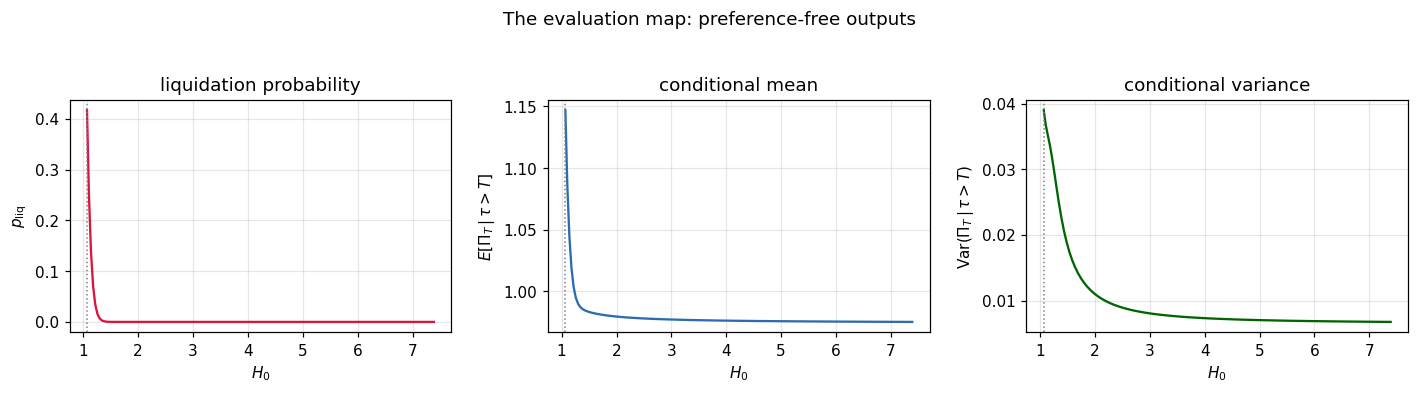

alpha= 0.5, delta= 0.0  ->  argmax at H0 = 1.0685, Phi = 1.1372
alpha= 2.0, delta= 0.0  ->  argmax at H0 = 1.0685, Phi = 1.1079
alpha= 2.0, delta= 0.5  ->  argmax at H0 = 2.7642, Phi = 0.9691

Same evaluation map, three different answers. The map is the model's output;
the answer is the investor's. But note where the conditional objective puts the answer:
near the thinnest buffer -- the survivorship artefact. Part XIII asks the question
on unconditional wealth instead: does the first unit of debt help at all?


In [6]:
# --- Part IV: the evaluation map, then a decision applied on top ----------
from optimal_long_short.carry import conditional_sharpe, objective_phi

fine = np.linspace(h0_min, 2.0, 60)
emap = pd.DataFrame(h0_liquidation_moment_report(params, fine, b=B, T=T, max_moment_order=2))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
axes[0].plot(emap["H0"], emap["p_liq"], color="crimson")
axes[0].set_ylabel(r"$p_{\rm liq}$"); axes[0].set_title("liquidation probability")
axes[1].plot(emap["H0"], emap["conditional_mean"], color="#2b6cb0")
axes[1].set_ylabel(r"$E[\Pi_T\,|\,\tau>T]$"); axes[1].set_title("conditional mean")
axes[2].plot(emap["H0"], emap["conditional_variance"], color="darkgreen")
axes[2].set_ylabel(r"$\mathrm{Var}(\Pi_T\,|\,\tau>T)$"); axes[2].set_title("conditional variance")
for a in axes:
    a.set_xlabel(r"$H_0$"); a.axvline(math.exp(h0_min), color="grey", ls=":", lw=1)
plt.suptitle("The evaluation map: preference-free outputs", y=1.04)
plt.tight_layout(); plt.show()

# the decision layer, applied afterwards -- three different investors, same map
for alpha, delta in [(0.5, 0.0), (2.0, 0.0), (2.0, 0.5)]:
    phi = np.array([objective_phi(r, alpha=alpha, delta=delta)
                    for r in emap.to_dict("records")])
    i = int(np.argmax(phi))
    print(f"alpha={alpha:>4}, delta={delta:>4}  ->  argmax at H0 = {emap['H0'][i]:.4f}, "
          f"Phi = {phi[i]:.4f}")
print("\nSame evaluation map, three different answers. The map is the model's output;")
print("the answer is the investor's. But note where the conditional objective puts the answer:")
print("near the thinnest buffer -- the survivorship artefact. Part XIII asks the question")
print("on unconditional wealth instead: does the first unit of debt help at all?")

---
# Part V. Addition #2 --- a real protocol data layer

**What changed.** `optimal_long_short/aave_hourly.py` (a subgraph fetcher),
`jobs/fetch_universe.py` (the entry point), and `data/AAVE/hourly_*.parquet` --- hourly history
for twelve Aave v3 Ethereum reserves, plus every reserve's on-chain configuration.

Before this, the repository's empirical content was one calibrated pair. Now there is a
universe, which is what makes Parts VI and IX possible at all.

## V.1 What a "reserve" is and what is recorded

A **reserve** is one asset's pool inside Aave: all the WETH supplied, all the WETH borrowed,
and the parameters governing it. For each reserve and each hour we store

| Column | Meaning |
|---|---|
| `supplied_USD`, `borrowed_USD` | pool size and how much of it is lent out |
| `lender_variable_apr` | the supply rate $r_s$, in **percent per year** |
| `borrower_variable_apr` | the borrow rate $r_b$, in **percent per year** |
| `utilization` | the subgraph's own $\text{borrowed}/\text{supplied}$ ratio |
| `price_usd` | oracle-implied price, from reserve TVL divided by token balance --- see the units caveat below |
| `TVL_USD` | total value locked, used for the liquidity ranking in Part VI |

and separately, per reserve, the **configuration**: $b$ (liquidation threshold),
$\mathrm{LTV}_{\max}$, the liquidation bonus $\lambda$, the reserve factor, and the three
rate-curve parameters we will need in Part IX.

**Two units traps, both real.**

1. The APR columns are percentages ($2.51$ means $2.51\%$), while every formula in this
   notebook wants decimals ($0.0251$). Every conversion in the code divides by $100$ explicitly
   for exactly this reason.
2. `price_usd` in the parquets written so far is *not* on a dollar scale --- the WETH column
   runs around $10^{-15}$, because the fetcher divided TVL by the token balance in its smallest
   unit. The fetcher now scales by $10^{\text{decimals}}$, so a fresh fetch writes true dollars,
   and `jobs/build_merged_4h.py` recomputes the headline prices from TVL and balance directly.
   The old scale does **not** affect anything downstream, because the only use of prices is the
   log **ratio**
   $Z=X_1-X_2$ and its increments, in which any constant scale factor cancels:
   $\log(\alpha S_1/\beta S_2)$ differs from $\log(S_1/S_2)$ by the constant $\log(\alpha/\beta)$,
   which vanishes on differencing. The plot below therefore shows the price **indexed to 1** at
   the window start. (The calibrated $S_{1,0}, S_{2,0}$ in `results/params_WBTC_WETH.json` are
   separately on a true USD scale.)

## V.2 Why prices come from the protocol, not an exchange

$S_{i,t}$ is taken from Aave's own oracle-implied value rather than a spot exchange. That is
deliberate: **liquidation is triggered by the oracle price, not by the market price**. If you
model with exchange prices you are modelling a barrier that the protocol does not use.

WETH hourly frame: 14,321 rows x 14 columns, 2025-01-01 -> 2026-08-20

                                supplied_USD       borrowed_USD  lender_variable_apr  borrower_variable_apr
datetime                                                                                                   
2026-08-20 15:00:00+00:00 4,954,696,801.5902 4,005,092,796.6221               1.4539                 2.1162
2026-08-20 16:00:00+00:00 5,056,925,623.9578 4,092,533,842.0429               1.4574                 2.1188
2026-08-20 17:00:00+00:00 5,030,756,648.3702 4,071,646,411.6544               1.4576                 2.1189

stored price_usd (WETH): 2.320e-15  -- written before the decimals fix
TVL / (balance / 1e18)    : 2,319.70 USD
Only log-differences are used, so the old constant scale cancels. See the note above.


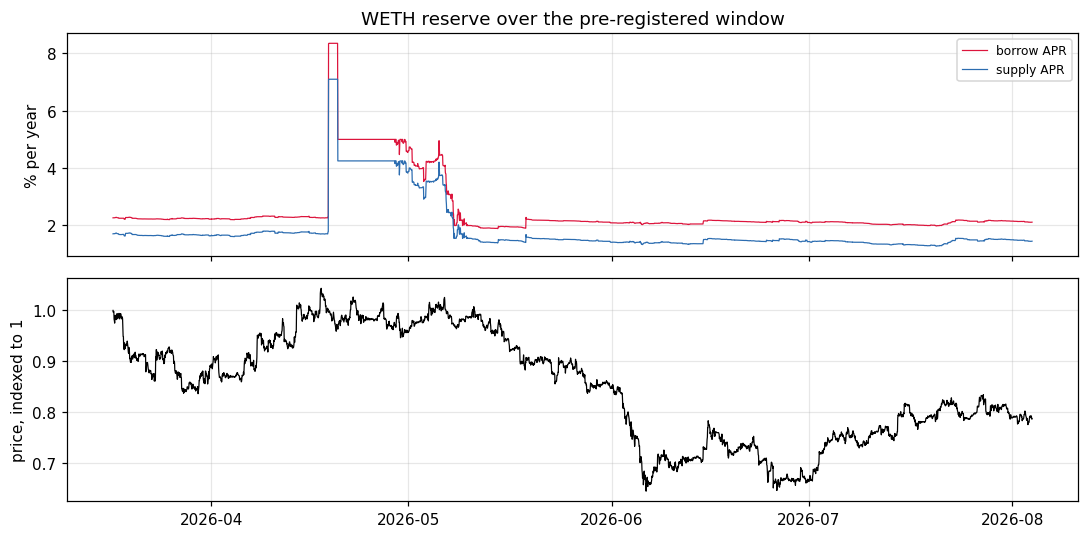


Contract terms available for every reserve (this is what Part VI screens on):
        baseLTVasCollateral  reserveLiquidationThreshold  liquidationBonus  reserveFactor  optimalUtilisationRate  variableRateSlope1  variableRateSlope2
symbol                                                                                                                                                   
WETH                 0.8050                       0.8300            0.0500         0.1500                  0.9000              0.0270              0.8000
WBTC                 0.7300                       0.7800            0.0500         0.5000                  0.4500              0.0400              3.0000
USDC                 0.7500                       0.7800            0.0450         0.1000                  0.9200              0.0550              0.6000


In [7]:
# --- Part V: what the data layer actually holds --------------------------
weth = panel["WETH"]
print(f"WETH hourly frame: {weth.shape[0]:,} rows x {weth.shape[1]} columns, "
      f"{weth.index[0]:%Y-%m-%d} -> {weth.index[-1]:%Y-%m-%d}\n")
print(weth[["supplied_USD", "borrowed_USD", "lender_variable_apr",
            "borrower_variable_apr"]].tail(3).to_string())
print(f"\nstored price_usd (WETH): {weth['price_usd'].iloc[-1]:.3e}  -- written before the decimals fix")
print(f"TVL / (balance / 1e18)    : {weth['TVL_USD'].iloc[-1] / (weth['token_balance'].iloc[-1] / 1e18):,.2f} USD")
print("Only log-differences are used, so the old constant scale cancels. See the note above.")

win = weth.loc[CFG.window_start:CFG.window_end]
fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
axes[0].plot(win.index, win["borrower_variable_apr"], lw=0.8, color="crimson", label="borrow APR")
axes[0].plot(win.index, win["lender_variable_apr"], lw=0.8, color="#2b6cb0", label="supply APR")
axes[0].set_ylabel("% per year"); axes[0].legend(fontsize=8)
axes[0].set_title("WETH reserve over the pre-registered window")
axes[1].plot(win.index, win["price_usd"] / win["price_usd"].iloc[0], lw=0.8, color="black")
axes[1].set_ylabel("price, indexed to 1")
plt.tight_layout(); plt.show()

print("\nContract terms available for every reserve (this is what Part VI screens on):")
print(configs.loc[["WETH", "WBTC", "USDC"],
                  ["baseLTVasCollateral", "reserveLiquidationThreshold", "liquidationBonus",
                   "reserveFactor", "optimalUtilisationRate", "variableRateSlope1",
                   "variableRateSlope2"]].to_string())

---
# Part VI. Addition #3 --- carry as an effective drift

**What changed.** A new module `optimal_long_short/carry.py` and a paper appendix (Appendix D),
containing Proposition "Carry is an effective drift".

## VI.1 The gap in the base model

Part I priced the position from spot *values* only. But a real Aave position is
interest-bearing on **both** legs at once:

* the collateral you supplied earns the **supply rate** $r_s$ --- your collateral grows;
* the debt you owe accrues the **borrow rate** $r_b$ --- your debt grows.

Both compound continuously through the protocol's indices. Ignoring them is ignoring the
entire reason people call this a *carry trade*.

## VI.2 The derivation

Hold $r_s$ and $r_b$ fixed over $[0,T]$ (we relax this in Part XI). Continuous compounding at
rate $r$ multiplies a value by $e^{rt}$, so the leg values become

$$V_{1,t} = n_1S_{1,0}\,e^{X_{1,t}}\,e^{r_s t},
\qquad
V_{2,t} = n_2S_{2,0}\,e^{X_{2,t}}\,e^{r_b t}.$$

Now redo §I.4 with these. The health factor is

$$H_t = \frac{b\,V_{1,t}}{V_{2,t}}
= \frac{b\,n_1S_{1,0}}{n_2S_{2,0}}\,\frac{e^{X_{1,t}}e^{r_st}}{e^{X_{2,t}}e^{r_bt}}
= H_0\,\exp\!\big(Z_t + (r_s-r_b)t\big),$$

where all we did was collect exponents. Taking logs,

$$\boxed{\;h_t \;=\; h_0 + Z_t + c\,t, \qquad c := r_s-r_b\;}$$

$c$ is the **net carry**. Compare with §I.4, $h_t=h_0+Z_t$: *the only change is a deterministic
straight line $ct$ added to the path.*

Since a straight line added to a process is the same as changing its drift, define the
**carry-adjusted log-prices**

$$\widetilde X_{i,t} := X_{i,t} + r_i t, \qquad r_1:=r_s,\ \ r_2:=r_b .$$

Each $\widetilde X_i$ is *still a Kou process*: adding $r_it$ changes $\mu_i^X$ and nothing
else --- same $\sigma_i$, same $\lambda_i$, same jump law. And by §II.5, $\mu_i^X$ is pinned to
$\mu_i$ through $\mu_i^X=\mu_i-\tfrac12\sigma_i^2-\lambda_i\chi_i$, in which $\sigma_i,\lambda_i,\chi_i$
are all unchanged. So shifting $\mu_i^X$ by $r_i$ is *exactly* shifting $\mu_i$ by $r_i$:

$$\boxed{\;(\mu_1,\mu_2)\;\longmapsto\;(\mu_1+r_s,\ \mu_2+r_b)\;}$$

**That is the whole proposition.** Every downstream object --- characteristic exponent, roots,
$3\times3$ barrier system, survival probability, killed moments --- takes $(\mu_1,\mu_2)$ as
input and does not care where they came from. So carry-adjusted sizing is the *existing* code
called at *shifted arguments*. `carry.apply_carry` is one line.

Two consequences that are easy to miss:

* Both effects are captured by the *single* substitution. The health factor picks up the
  **net** carry $c=r_s-r_b$ (via $Z$), while the terminal payoff picks up the **per-leg**
  accruals $e^{r_sT}$ and $e^{r_bT}$ separately (via each $\widetilde X_i$). One substitution,
  both effects, consistently.
* The admissibility bound $k\eta_{2,+}<1$ of §III.3 is untouched, because $\eta_{2,+}$ is not a
  drift. Nothing about the moment structure changes.

**Direction of the effect.** $c>0$ tilts $h_t$ upward, away from the barrier, so
$p_{\mathrm{surv}}$ rises at fixed $h_0$: positive carry works like extra cushion. $c<0$ does
the reverse. Whether the effect is *large* is a quantitative question --- Part VII.

## VI.3 The three ways to pick a rate

`carry.RateSource` names them explicitly, because the choice is an assumption, not a fact:

| Source | What it uses | When it is right |
|---|---|---|
| `SPOT` | today's APR, held constant | short horizons |
| `REALIZED` | trailing mean APR over the window | when the pool is stable |
| `CIR_THETA` | the long-run mean of a fitted mean-reverting rate model | never, here --- see Part IX |

The docstring warns you off `CIR_THETA` explicitly. Part IX explains why those fits are broken,
and what replaced them.

## VI.4 A second sizing rule that avoids the whole argument

`carry.size_for_target_pliq` implements a practitioner's rule: forget objectives, just pick the
buffer $h_0$ such that

$$p_{\mathrm{liq}}(h_0) \;=\; \text{(target, e.g. 5\%)} .$$

Why this is well posed: **more cushion is always safer**, so $p_{\mathrm{liq}}$ is strictly
decreasing in $h_0$; a strictly monotone function crosses any level at most once, so the root
is unique and plain **bisection** finds it. (Bisection: keep an interval known to bracket the
root, halve it, keep the half that still brackets. Each step halves the error, so $60$ steps
give $2^{-60}$ --- machine precision.)

The search is deliberately floored at $h_0=0$ ($H_0=1$): below that the position is *already*
liquidated, $p_{\mathrm{liq}}=1$, and the Laplace inversion is ill-conditioned.

In [8]:
# --- Part VI: carry is a drift shift, verified ---------------------------
from optimal_long_short.carry import (CarryLeg, CarrySpec, apply_carry,
                                      optimal_carry_h0, size_for_target_pliq)

# Realized window-average rates for the calibrated WBTC-collateral / WETH-debt book.
r_s = float(np.mean(panel["WBTC"].loc[CFG.window_start:CFG.window_end,
                                      "lender_variable_apr"])) / 100.0
r_b = float(np.mean(panel["WETH"].loc[CFG.window_start:CFG.window_end,
                                      "borrower_variable_apr"])) / 100.0
spec = CarrySpec(collateral=CarryLeg("WBTC", r_s), debt=CarryLeg("WETH", r_b))
carried = apply_carry(params, spec)

print(f"supply APR on WBTC collateral  r_s = {r_s:8.5f}  ({100*r_s:.4f}%)")
print(f"borrow APR on WETH debt        r_b = {r_b:8.5f}  ({100*r_b:.4f}%)")
print(f"net carry                      c   = {spec.net_carry:8.5f}  "
      f"({100*spec.net_carry:.4f}%)   <-- you PAY to hold this book\n")
print("The proposition says mu_i moves by exactly r_i and nothing else moves:")
print(f"  mu1: {params.mu1:.6f} + {r_s:.6f} = {params.mu1 + r_s:.6f}   got {carried.mu1:.6f}")
print(f"  mu2: {params.mu2:.6f} + {r_b:.6f} = {params.mu2 + r_b:.6f}   got {carried.mu2:.6f}")
print(f"  sigma1 unchanged: {params.sigma1 == carried.sigma1};  "
      f"lam2 unchanged: {params.lam2 == carried.lam2};  "
      f"eta2_pos unchanged: {params.eta2_pos == carried.eta2_pos}")

supply APR on WBTC collateral  r_s =  0.00006  (0.0060%)
borrow APR on WETH debt        r_b =  0.02512  (2.5116%)
net carry                      c   = -0.02506  (-2.5055%)   <-- you PAY to hold this book

The proposition says mu_i moves by exactly r_i and nothing else moves:
  mu1: -0.313737 + 0.000060 = -0.313676   got -0.313676
  mu2: -0.416787 + 0.025116 = -0.391671   got -0.391671
  sigma1 unchanged: True;  lam2 unchanged: True;  eta2_pos unchanged: True


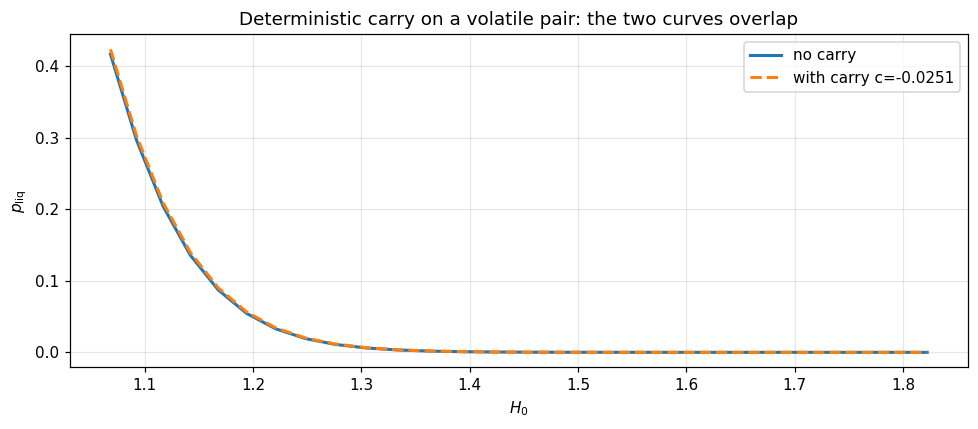

largest gap in p_liq across the grid: 6.76e-03



size_for_target_pliq(5%):  h0* = 0.1829, H0* = 1.2007, leverage = 2.854x, realised p_liq = 0.05000, target attained = True


In [9]:
# --- Part VI: how much does carry actually move survival? ----------------
grid = np.linspace(h0_min, 0.6, 25)
no_carry = pd.DataFrame(h0_liquidation_moment_report(params, grid, b=B, T=T, max_moment_order=1))
w_carry = pd.DataFrame(h0_liquidation_moment_report(carried, grid, b=B, T=T, max_moment_order=1))

fig, ax = plt.subplots()
ax.plot(no_carry["H0"], no_carry["p_liq"], lw=2, label="no carry")
ax.plot(w_carry["H0"], w_carry["p_liq"], lw=2, ls="--", label=f"with carry c={spec.net_carry:.4f}")
ax.set_xlabel(r"$H_0$"); ax.set_ylabel(r"$p_{\rm liq}$")
ax.set_title("Deterministic carry on a volatile pair: the two curves overlap")
ax.legend(); plt.tight_layout(); plt.show()

print(f"largest gap in p_liq across the grid: "
      f"{np.max(np.abs(w_carry['p_liq'] - no_carry['p_liq'])):.2e}")

# the target-p_liq sizing rule
row = size_for_target_pliq(params, spec, 0.05, b=B, T=T)
print(f"\nsize_for_target_pliq(5%):  h0* = {row['h0']:.4f}, H0* = {row['H0']:.4f}, "
      f"leverage = {row['initial_leverage']:.3f}x, realised p_liq = {row['p_liq']:.5f}, "
      f"target attained = {bool(row['target_attained'])}")

---
# Part VII. Addition #4 --- the pre-registered screen, and the finding that carry is inert

**What changed.** A new module `optimal_long_short/screen.py`, the output file
`results/pair_cross_section.csv`, and paper Appendix D.2. Part VI showed carry is *free* to include.
This part asks whether it *matters*, and answers no.

## VII.1 Pre-registration: why the screen is fixed in advance

Suppose you tried all pairs and reported the one where carry looked most impressive. Your
result would be an artefact of searching, not a fact about DeFi. This is **selection bias**,
and with $37$ candidate pairs it is not a small effect.

The defence is to fix the selection rule **before looking at any result**, and then report
**every** pair that survives. The rule here is:

1. Universe fixed in advance --- blue-chip majors and their canonical wrappers. No governance
   tokens, no yield-bearing or principal-token wrappers.
2. Not frozen and not paused (a frozen reserve cannot be entered).
3. Listed for the entire estimation window --- otherwise the sample period differs by asset.
4. Ranked by **USD TVL at the window start**, keep the top $8$. Note *at the start*: using
   end-of-window size would be using information you did not have when you chose.
5. Admissibility from the contract: a collateral leg needs $\mathrm{LTV}_{\max}>0$ and
   collateral use enabled; a debt leg needs borrowing enabled.

Every criterion is about **liquidity and protocol permissions**. None is about realised
performance. Eight reserves survive; ordered pairs (collateral, debt) with the two legs
distinct give $37$ pairs, and all $37$ are reported.

## VII.2 The diagnostic: carry against the barrier

We need one number saying "does carry matter for this pair?". Compare the two forces acting
on $h_t = h_0 + Z_t + ct$ over the horizon $T$, using the scaling from §II.1:

* **Carry** is deterministic and accumulates linearly: over $[0,T]$ it moves the buffer by
  $c\,T$.
* **Diffusion** is random and accumulates in standard deviation like $\sqrt{\,\cdot\,}$: its
  typical size over $[0,T]$ is $\sigma_Z\sqrt T$.

Their ratio is the **carry-to-barrier ratio**

$$\boxed{\;\mathrm{CB} \;=\; \frac{c\,T}{\sigma_Z\sqrt T} \;=\; \frac{c}{\sigma_Z}\sqrt{T}\;}$$

It is dimensionless: **the number of barrier standard deviations that carry is worth over the
horizon.** Interpretation:

* $|\mathrm{CB}| \ll 1$: carry is lost in the noise. It cannot change a sizing decision,
  *whatever its sign*.
* $|\mathrm{CB}| \sim 1$: carry moves the position by as much as a typical month of price
  noise, and must be modelled.

The middle expression $\frac{c}{\sigma_Z}\sqrt T$ also tells you the *only* two ways to make
carry matter: a big rate, or a **small $\sigma_Z$**.

## VII.3 What the 37 pairs say

Two findings, both against the way carry is usually talked about.

**(a) For every volatile pair, carry is negligible.** Across all crypto-vs-crypto pairs
$\mathrm{CB}$ sits between about $-0.03$ and $+0.02$ --- a few percent of one standard
deviation over a month. The exception is exactly where the formula predicts it: stable-vs-stable
pairs have $\sigma_Z$ around $0.002$--$0.004$ instead of $0.35$--$0.55$, roughly $100\times$
smaller, and there $\mathrm{CB}$ reaches $-0.96$.

But notice the trap in that exception. At $\sigma_Z=0.0043$ and $h_0^{\min}=0.039$, the barrier
sits $h_0/(\sigma_Z\sqrt T) \approx 31$ standard deviations away. A $31$-sigma Gaussian event
has probability around $10^{-211}$; the measured liquidation risk is *entirely* jumps and
depegs, not diffusion. So the one place carry matters is the one place the diffusive reading is
least trustworthy --- which is what motivates the depeg overlay in Part VIII.

**(b) The leveraged long-crypto book pays carry rather than earning it.** Wrapped BTC pays
$0.00$--$0.01\%$ as collateral, WETH about $1.9\%$, while borrowing costs $2.5$--$4.5\%$. So
every crypto-collateral pair with a *stablecoin or ETH* debt leg has negative net carry ---
between roughly $-1.8\%$ and $-4.5\%$. The position is **short the liquidation barrier and is
not paid for it.**

The exceptions are worth naming rather than hiding, because they are informative: a pair whose
**debt leg is wrapped BTC** does earn positive carry (WETH collateral / WBTC debt is about
$+1.6\%$), simply because the BTC reserves are barely borrowed, so $r_b\approx0.3\%$. But that
is also the leg with $U\approx0.04$ against $U_{\mathrm{opt}}=0.45$ --- and the cell below shows
its $\mathrm{CB}$ is at most $0.012$. Positive but still inert. That observation is the seed
of Part XII.

In [10]:
# --- Part VII: the screen ------------------------------------------------
from optimal_long_short.screen import apply_screen, pair_cross_section

screen = apply_screen(panel, configs, CFG)
print("Pre-registered screen (ranked by TVL at the window START):\n")
print(screen[["tvl_usd_at_start", "rank", "in_universe", "ltv", "liq_threshold",
              "admissible_collateral", "admissible_debt"]].to_string())
print(f"\ncollateral-admissible: {int(screen['admissible_collateral'].sum())},  "
      f"debt-admissible: {int(screen['admissible_debt'].sum())}")

Pre-registered screen (ranked by TVL at the window START):

         tvl_usd_at_start  rank  in_universe    ltv  liq_threshold  admissible_collateral  admissible_debt
symbol                                                                                                    
WETH   6,891,116,652.6718     1         True 0.8050         0.8300                   True             True
USDT   5,220,245,758.2202     2         True 0.7500         0.7800                   True             True
weETH  5,077,528,509.4125     3         True 0.7750         0.8000                   True            False
wstETH 3,905,314,696.8875     4         True 0.7850         0.8100                   True            False
USDC   3,549,228,464.3469     5         True 0.7500         0.7800                   True             True
WBTC   3,100,178,912.2066     6         True 0.7300         0.7800                   True             True
cbBTC  1,928,398,994.1953     7         True 0.7300         0.7800                  

37 ordered (collateral, debt) pairs -- ALL of them reported.

Most carry-sensitive pairs (largest |CB|):
collateral debt  sigma_Z    r_s    r_b  net_carry  carry_over_barrier  debt_frac_stressed
      USDT USDC   0.0043 0.0312 0.0454    -0.0142             -0.9573              0.1044
      USDT USDe   0.0024 0.0312 0.0363    -0.0051             -0.6179              0.0524
      USDC USDT   0.0043 0.0368 0.0411    -0.0043             -0.2916              0.0848
     cbBTC USDC   0.4131 0.0000 0.0454    -0.0454             -0.0317              0.1044
      USDC USDe   0.0043 0.0368 0.0363     0.0005              0.0314              0.0524
      WBTC USDC   0.4193 0.0001 0.0454    -0.0454             -0.0312              0.1044

The calibrated benchmark and its neighbours:
collateral  debt  sigma_Z    r_s    r_b  net_carry  carry_over_barrier  debt_frac_stressed
      WBTC  USDC   0.4193 0.0001 0.0454    -0.0454             -0.0312              0.1044
      WBTC  USDT   0.4193 0.0001 0.04

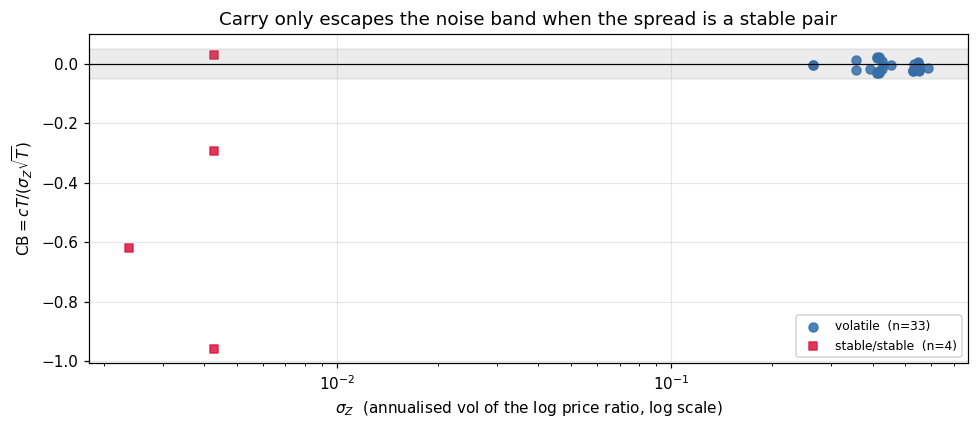


volatile pairs: CB in [-0.032, +0.024]
crypto-collateral pairs        : net carry in [-0.0454, +0.0156]
  ... with a non-BTC debt leg  : net carry in [-0.0454, -0.0176]  -- every one negative
  ... with a BTC debt leg      : net carry in [-0.0036, +0.0156]  -- positive, but |CB| <= 0.012: still inert


In [11]:
# --- Part VII: the 37-pair cross-section and the CB diagnostic -----------
xs = pair_cross_section(panel, configs, screen, CFG)
print(f"{len(xs)} ordered (collateral, debt) pairs -- ALL of them reported.\n")

STABLE = {"USDC", "USDT", "USDe", "DAI", "GHO"}
xs["kind"] = np.where(xs["collateral"].isin(STABLE) & xs["debt"].isin(STABLE),
                      "stable/stable", "volatile")

cols = ["collateral", "debt", "sigma_Z", "r_s", "r_b", "net_carry",
        "carry_over_barrier", "debt_frac_stressed"]
print("Most carry-sensitive pairs (largest |CB|):")
print(xs.reindex(xs["carry_over_barrier"].abs().sort_values(ascending=False).index)
        .head(6)[cols].to_string(index=False))
print("\nThe calibrated benchmark and its neighbours:")
print(xs[xs["collateral"].isin(["WBTC", "WETH", "cbBTC"])][cols].head(8).to_string(index=False))

fig, ax = plt.subplots()
for kind, m, col in [("volatile", "o", "#2b6cb0"), ("stable/stable", "s", "crimson")]:
    sub = xs[xs["kind"] == kind]
    ax.scatter(sub["sigma_Z"], sub["carry_over_barrier"], marker=m, s=34, color=col,
               label=f"{kind}  (n={len(sub)})", alpha=0.85)
ax.set_xscale("log")
ax.axhspan(-0.05, 0.05, color="grey", alpha=0.15)
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel(r"$\sigma_Z$  (annualised vol of the log price ratio, log scale)")
ax.set_ylabel(r"$\mathrm{CB}=cT/(\sigma_Z\sqrt{T})$")
ax.set_title("Carry only escapes the noise band when the spread is a stable pair")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

vol = xs[xs["kind"] == "volatile"]
print(f"\nvolatile pairs: CB in [{vol['carry_over_barrier'].min():+.3f}, "
      f"{vol['carry_over_barrier'].max():+.3f}]")
BTC = {"WBTC", "cbBTC", "tBTC"}
cc = xs[~xs["collateral"].isin(STABLE)]
print(f"crypto-collateral pairs        : net carry in "
      f"[{cc['net_carry'].min():+.4f}, {cc['net_carry'].max():+.4f}]")
print(f"  ... with a non-BTC debt leg  : net carry in "
      f"[{cc[~cc['debt'].isin(BTC)]['net_carry'].min():+.4f}, "
      f"{cc[~cc['debt'].isin(BTC)]['net_carry'].max():+.4f}]  -- every one negative")
print(f"  ... with a BTC debt leg      : net carry in "
      f"[{cc[cc['debt'].isin(BTC)]['net_carry'].min():+.4f}, "
      f"{cc[cc['debt'].isin(BTC)]['net_carry'].max():+.4f}]  -- positive, but |CB| <= "
      f"{cc[cc['debt'].isin(BTC)]['carry_over_barrier'].abs().max():.3f}: still inert")

---
# Part VIII. Addition #5 --- the depeg overlay

**What changed.** `carry.depeg_scenario`, and paper Appendix D.4. Part VII ended with a warning:
the pairs where carry matters are stable pairs, whose apparent safety rests on a tiny
$\sigma_Z$. This part stress-tests exactly that.

## VIII.1 What a depeg is

A **peg** is a promise that one token is worth a fixed amount of something else --- USDC is
supposed to be one dollar, wstETH is supposed to track ETH. A **depeg** is the promise
breaking: in March 2023, USDC traded at $\$0.88$ for two days after a bank failure.

The base model cannot produce that. It gives $Z$ a small $\sigma_Z$ and a jump law fitted to
ordinary days; a $12\%$ instant collateral haircut is not in it.

## VIII.2 The derivation --- three lines, no new machinery

Let the collateral lose a fraction $d\in[0,1)$ of its value instantly. Then $V_1 \mapsto
(1-d)V_1$, the debt is untouched, so from $H = bV_1/V_2$,

$$H \;\longmapsto\; (1-d)\,H .$$

Taking logs, $\log H \mapsto \log H + \log(1-d)$. Since $\log(1-d)<0$ for $d>0$, the effect is a
**downward shift of the buffer by a fixed amount**:

$$\boxed{\;h_0 \;\longmapsto\; h_0^{\text{eff}} \;=\; h_0 + \log(1-d)\;}$$

And that is the whole overlay. A depegged position is **the same holdings evaluated at a
smaller buffer**, so you re-run the *existing* evaluation map at $h_0^{\text{eff}}$. Nothing is
re-derived; this is the evaluation map of Part IV paying for itself.

Two boundary cases the code handles explicitly:

* If $h_0^{\text{eff}} \le \log b$, the shock alone puts $H<b\cdot\!$(nothing left): the
  position is liquidated instantly and the row is reported with $p_{\mathrm{liq}}=1$.
* $d=0$ is the unshocked baseline, so the first row is always the original position.

*(Implementation note: the code uses `math.log1p(-d)` rather than `math.log(1-d)`. For small
$d$, computing $1-d$ first loses precision --- $1-10^{-16}$ rounds to $1$ --- while `log1p` is
accurate down to the last bit. Small point, but it is why the line looks the way it does.)*

## VIII.3 Why this is a scenario overlay and not a jump

It would be tempting to put depegs into the jump law. The module deliberately does not,
for two reasons:

1. **Keeps the base dynamics honest.** $X_1,X_2$ stay a pure price model fitted to price data.
   A depeg is a different kind of event with a different frequency; mixing them would let a
   rare-event assumption contaminate every ordinary calculation.
2. **Frequencies are not estimable.** With a handful of historical depegs you cannot estimate
   an intensity. A scenario answers "what if?", which is the honest question.

The paper is explicit that a full treatment would let depegs and the rate regime of Part XI
**co-move**, since the deleveraging that breaks a peg is also what drives utilization through
its kink. That is left open.

## VIII.4 The uncomfortable conclusion

Small $\sigma_Z$ makes high leverage look affordable. High leverage means a thin buffer $h_0$.
A thin buffer is exactly what a fixed haircut $\log(1-d)$ wipes out. **The property that makes
a stable-pair book attractive is the property that makes it depeg-fragile**, and since Part VII
showed carry there is at most $\sim\!1$ barrier standard deviation, no amount of carry pays for
it.

Position held at h0 = 0.25 (H0 = 1.2840), then hit by an instant collateral haircut d:



 depeg_fraction  h0_eff  H0_eff  p_liq  conditional_mean  instant_liquidation
         0.0000  0.2500  1.2840 0.0098            0.9885               0.0000
         0.0100  0.2399  1.2712 0.0127            0.9900               0.0000
         0.0200  0.2298  1.2583 0.0165            0.9918               0.0000
         0.0500  0.1987  1.2198 0.0349            1.0001               0.0000
         0.1000  0.1446  1.1556 0.1115            1.0303               0.0000
         0.1500  0.0875  1.0914 0.3078            1.1016               0.0000
         0.2000  0.0269  1.0272 0.7065            1.2571               0.0000

check at d=0.1:  h0 + log(1-d) = 0.25 + -0.105361 = 0.144639   (code gives 0.144639)


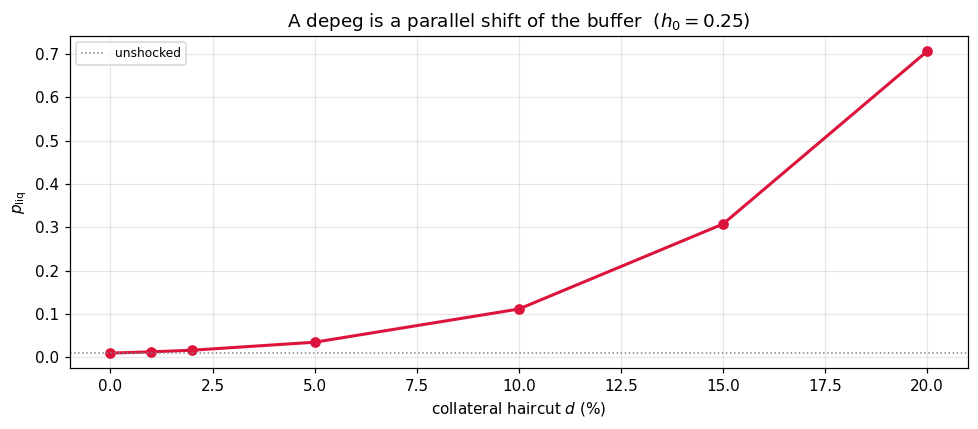

In [12]:
# --- Part VIII: depeg on a levered book ----------------------------------
from optimal_long_short.carry import depeg_scenario

h0_stress = 0.25
depegs = [0.0, 0.01, 0.02, 0.05, 0.10, 0.15, 0.20]
dp = pd.DataFrame(depeg_scenario(params, spec, h0_stress, depegs, b=B, T=T,
                                 max_moment_order=2))

print(f"Position held at h0 = {h0_stress} (H0 = {math.exp(h0_stress):.4f}), "
      f"then hit by an instant collateral haircut d:\n")
print(dp[["depeg_fraction", "h0_eff", "H0_eff", "p_liq", "conditional_mean",
          "instant_liquidation"]].to_string(index=False))

# verify the derivation term by term
d_chk = 0.10
print(f"\ncheck at d={d_chk}:  h0 + log(1-d) = {h0_stress} + {math.log1p(-d_chk):.6f} = "
      f"{h0_stress + math.log1p(-d_chk):.6f}   (code gives "
      f"{float(dp.loc[dp['depeg_fraction'] == d_chk, 'h0_eff'].iloc[0]):.6f})")

fig, ax = plt.subplots()
ax.plot(100 * dp["depeg_fraction"], dp["p_liq"], "o-", color="crimson", lw=2)
ax.set_xlabel("collateral haircut $d$ (%)"); ax.set_ylabel(r"$p_{\rm liq}$")
ax.set_title(fr"A depeg is a parallel shift of the buffer  ($h_0={h0_stress}$)")
ax.axhline(float(dp["p_liq"].iloc[0]), color="grey", ls=":", lw=1, label="unshocked")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

---
# Part IX. Addition #6 --- the rate curve and the utilization model

**What changed.** A new module `optimal_long_short/rate_curve.py`, replacing the CIR and
CIR-with-jumps fits in `results/cir_usdc_weth_aave_v3.csv` and `jcir_usdc_weth_aave_v3.csv`.
This is the addition with the sharpest "we were doing it wrong" character, so we go slowly.

## IX.1 Utilization, and Aave's rate curve

Define the reserve's **utilization**

$$U \;=\; \frac{\text{total borrowed}}{\text{total supplied}} \;\in\; [0,1].$$

$U=0$: nobody is borrowing. $U=1$: every deposited token is lent out and *no supplier can
withdraw*. Aave prices that scarcity with a **piecewise-linear, kinked** borrow rate:

$$\boxed{\;r_b(U)=
\begin{cases}
r_0 + s_1\dfrac{U}{U_{\mathrm{opt}}}, & U \le U_{\mathrm{opt}},\\[10pt]
r_0 + s_1 + s_2\dfrac{U-U_{\mathrm{opt}}}{1-U_{\mathrm{opt}}}, & U > U_{\mathrm{opt}} .
\end{cases}\;}$$

Reading the four parameters, all published on-chain per reserve:

* $r_0$ --- **base rate**, charged at $U=0$ (often $0$).
* $U_{\mathrm{opt}}$ --- the **kink**, the utilization the protocol wants to sit at
  ($0.92$ for USDC, $0.90$ for WETH, $0.45$ for WBTC).
* $s_1$ --- rate added across the whole *first* segment, so slope $s_1/U_{\mathrm{opt}}$.
  Typically $0.027$--$0.055$: gentle.
* $s_2$ --- rate added across the whole *second* segment, so slope $s_2/(1-U_{\mathrm{opt}})$.
  Published $s_2$ is $0.60$--$0.80$ for WETH and stables and $3.00$ for wrapped BTC.

At $U_{\mathrm{opt}}$ the slope multiplies by
$\frac{s_2/(1-U_{\mathrm{opt}})}{s_1/U_{\mathrm{opt}}}$. For USDC that is
$\frac{0.6/0.08}{0.055/0.92} \approx 125$. **The rate is continuous but its derivative jumps by
two orders of magnitude.** The kink is not a nuisance; it is the design.

The supplier is paid out of what borrowers pay, minus the protocol's cut:

$$r_s(U) \;=\; U\,r_b(U)\,(1-\text{reserve factor}).$$

The factor $U$ appears because interest is charged only on the borrowed fraction but shared
across *all* suppliers. Note that $U \cdot r_b(U)$ is a product of two increasing functions,
hence **convex** --- remember this for Part XII.

## IX.2 Why the old CIR fits were broken

The **CIR** (Cox--Ingersoll--Ross) model is the standard textbook short-rate process:

$$dr_t \;=\; \kappa(\theta-r_t)\,dt \;+\; \sigma\sqrt{r_t}\,dW_t,$$

with $\kappa$ the mean-reversion speed, $\theta$ the long-run level, $\sigma$ the volatility.
The $\sqrt{r_t}$ keeps $r$ from going negative. Fitting it, and a jump variant (JCIR), to the
Aave rate series produced three genuinely damning symptoms:

| Symptom | Value in `results/*.csv` | Why it is a problem |
|---|---|---|
| $\theta$ **not economically possible** | $\theta=4.98$ for the USDC series | a long-run *interest rate* of $498\%$ per year |
| $\theta$ **pinned at the optimiser bound** | $\theta=2.0000$ exactly, both series | that is not a fit; the search hit a wall and stopped |
| **Feller condition violated** (JCIR, USDC) | $2\kappa\theta=13.90$ vs $\sigma^2=72.33$ | the fitted "interest rate" can reach $0$ |
| **jumps invented** | $\lambda_{\rm jump}\approx 68$/yr, $204$ detected | needed to explain a kink that is deterministic |

*The Feller condition.* For CIR, $0$ is unattainable if and only if $2\kappa\theta \ge \sigma^2$.
The intuition: near $r=0$ the upward push is $\kappa\theta\,dt$ and the noise is
$\sigma\sqrt r\,dW$; the condition says the push wins. Violating it means your fitted process
can hit zero, which the data never does.

**One symptom that is *not* evidence, and it is worth saying so.** The fitted $\kappa$ is huge:
$2089$/yr, a mean-reversion half-life of $\ln2/\kappa\approx 3$ hours. That looks damning until
you fit the *replacement* model to the same hourly data and find it also reports a half-life of
a few hours (see the cell below). Fast reversion at hourly frequency is a real property of
these series --- bots arbitrage utilization back quickly --- not an artefact of the wrong model.
Being clear about which symptoms discriminate and which do not is the difference between a
diagnosis and a list of complaints.

**The diagnosis is structural, not numerical.** Aave's borrow rate *is not a stochastic process
at all*. It is a **deterministic function of $U$**. Fitting a smooth affine diffusion to a
*kinked transform of a bounded state* manufactures both pathologies:

* the **kink** looks like jumps: the rate's *speed* changes discontinuously, and a smooth
  diffusion can only reproduce that by inventing a jump component;
* the **flat first segment** looks like a rate that barely moves, so the estimator pushes
  $\theta$ out to absurd values and against its bounds trying to reconcile the two segments.

**The fix:** model the thing that is actually random --- $U$ --- and push it through the known,
deterministic curve.

## IX.3 Inverting the curve: the borrow rate is a sufficient statistic

$r_b$ is strictly increasing in $U$ (both $s_1,s_2>0$), so it is invertible. Solving each branch
for $U$:

*Below the kink,* $r = r_0 + s_1U/U_{\mathrm{opt}} \Rightarrow U = U_{\mathrm{opt}}(r-r_0)/s_1$.

*Above,* $r = r_0+s_1+s_2\frac{U-U_{\mathrm{opt}}}{1-U_{\mathrm{opt}}}
\Rightarrow U = U_{\mathrm{opt}} + (1-U_{\mathrm{opt}})\frac{r-r_0-s_1}{s_2}$.

The branch is chosen by comparing $r$ with the kink rate $r_0+s_1$. That is
`rate_curve.implied_utilization`, and it means **you never need to measure utilization
directly** --- the observed rate already tells you.

**Why bother, when the subgraph reports utilization?** Because the reported ratio
$\text{borrowed}_{\rm USD}/\text{supplied}_{\rm USD}$ is *biased upward*. It mixes
USD-converted aggregates across sub-markets and timestamps, and over the window it reports for
USDC a mean of $0.880$ and a maximum that **saturates at exactly $1.000$** --- meaning "every
deposited token is lent out and no supplier can withdraw", which simply did not happen. The
curve-implied series gives $0.676$ and $0.931$.

The consequence is not cosmetic. The naive measure calls $25.3\%$ of hours "stressed" when the
curve says $10.4\%$: a $2.4\times$ overstatement of *exactly the event* Part XI is about. As a
control, in the flat region where the two must agree, they do --- correlation $1.0000$ for WBTC,
against $0.81$ for USDC where the bias bites.

## IX.4 The Jacobi diffusion: a process that respects $[0,1]$

$U$ is a **fraction**: it lives in $[0,1]$. CIR is a half-line process, bounded below at $0$ but
with no mechanism at all to respect $U\le 1$. The right object is the **Jacobi** (or
Wright--Fisher) diffusion:

$$\boxed{\;dU_t \;=\; \kappa(\theta-U_t)\,dt \;+\; \sigma\sqrt{U_t(1-U_t)}\,dW_t\;}$$

Compare the two diffusion coefficients:

$$\text{CIR: } \sigma\sqrt{U} \qquad\text{vs}\qquad \text{Jacobi: } \sigma\sqrt{U(1-U)} .$$

The Jacobi factor vanishes at **both** ends. At $U\to 0$ and at $U\to 1$ the noise switches off
and only the drift $\kappa(\theta-U)$ remains, pointing inward. The process is trapped in
$[0,1]$ by construction --- exactly as a fraction must be.

**Boundary conditions.** The Feller-type condition becomes two conditions, one per boundary:

$$2\kappa\theta \ge \sigma^2 \ \ (\text{lower}), \qquad 2\kappa(1-\theta) \ge \sigma^2 \ \ (\text{upper}).$$

They are the mirror image of each other; each says the inward drift beats the local noise.

**Stationary law.** The long-run distribution of $U$ is $\mathrm{Beta}(a,b)$ with

$$a=\frac{2\kappa\theta}{\sigma^2}, \qquad b=\frac{2\kappa(1-\theta)}{\sigma^2},$$

which is the natural distribution on $[0,1]$, with mean $a/(a+b)=\theta$ and variance
$ab/[(a+b)^2(a+b+1)]$. This closed form is what makes Part XII's integral computable.

**Estimation.** `fit_jacobi` uses an Euler pseudo-likelihood, which is just a regression.
Discretise: $\Delta U_t \approx \kappa\theta\,\Delta t - \kappa\,\Delta t\,U_t + \text{noise}$.
That is a straight line in $U_t$, so regress $\Delta U$ on $U$:

$$\text{intercept}=\kappa\theta\,\Delta t, \qquad \text{slope}=-\kappa\,\Delta t
\quad\Longrightarrow\quad \kappa = -\frac{\text{slope}}{\Delta t},\quad
\theta = \frac{\text{intercept}}{\kappa\Delta t}.$$

Then $\sigma$ comes from the residuals, divided by the diffusion factor to undo the
heteroskedasticity: $\widehat\sigma^2 = \frac{1}{n}\sum \frac{e_i^2}{U_i(1-U_i)\Delta t}$.

**The point of doing it this way:** $\kappa$ and $\theta$ are read off a linear regression.
There is no optimiser, hence no bound for $\theta$ to get pinned against, and $\theta$ is a
utilization --- a number in $[0,1]$ --- so "$\theta=4.98$" is not even expressible. The specific
pathologies that broke the CIR fit cannot occur.

What you *should* check, and what the cell below checks, is whether the fit is internally
coherent: are both boundaries unattainable, and does the implied stationary Beta law match the
sample mean and spread? Those are the tests the CIR fits fail and this one passes. The fast
mean reversion survives --- as flagged above, that is a fact about hourly data, not a defect.

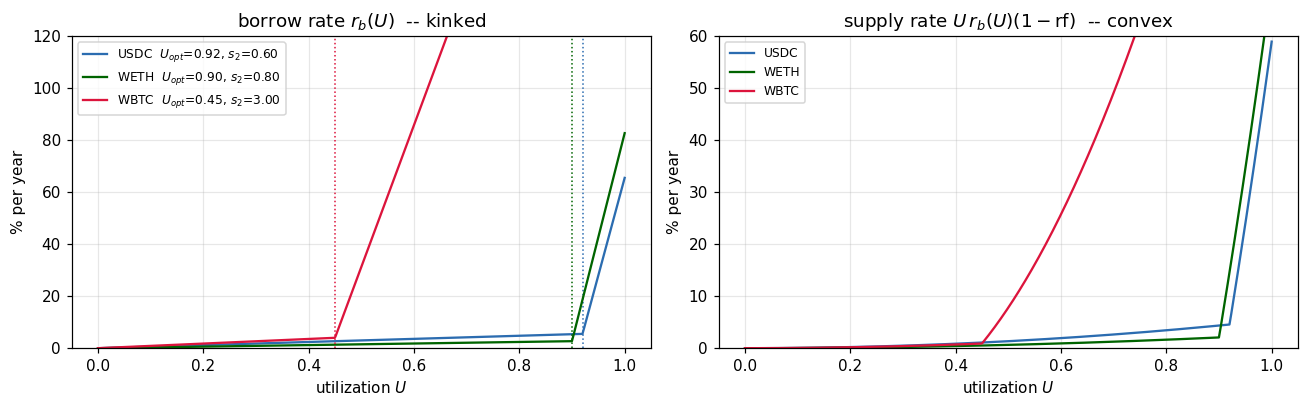

USDC: slope below the kink = s1/U_opt = 0.0598
      slope above the kink = s2/(1-U_opt) = 7.5000
      slope multiplies by 125x at U_opt = 0.92


In [13]:
# --- Part IX: the kinked rate curve --------------------------------------
from optimal_long_short.rate_curve import (fit_jacobi, implied_utilization, regime_summary)

u_ax = np.linspace(0, 1, 600)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for sym, col in [("USDC", "#2b6cb0"), ("WETH", "darkgreen"), ("WBTC", "crimson")]:
    cv = published_curve(configs, sym)
    rf = float(configs.loc[sym, "reserveFactor"])
    axes[0].plot(u_ax, [100 * cv.borrow_rate(u) for u in u_ax], color=col,
                 label=f"{sym}  $U_{{opt}}$={cv.u_opt:.2f}, $s_2$={cv.slope2:.2f}")
    axes[0].axvline(cv.u_opt, color=col, ls=":", lw=1)
    axes[1].plot(u_ax, [100 * cv.supply_rate(u, rf) for u in u_ax], color=col, label=sym)
axes[0].set_ylim(0, 120); axes[0].set_title(r"borrow rate $r_b(U)$  -- kinked")
axes[1].set_ylim(0, 60); axes[1].set_title(r"supply rate $U\,r_b(U)(1-\mathrm{rf})$  -- convex")
for a in axes:
    a.set_xlabel("utilization $U$"); a.set_ylabel("% per year"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

cv = published_curve(configs, "USDC")
below, above = cv.slope1 / cv.u_opt, cv.slope2 / (1 - cv.u_opt)
print(f"USDC: slope below the kink = s1/U_opt = {below:.4f}")
print(f"      slope above the kink = s2/(1-U_opt) = {above:.4f}")
print(f"      slope multiplies by {above/below:.0f}x at U_opt = {cv.u_opt}")

In [14]:
# --- Part IX: inverting the curve beats the reported ratio ---------------
rows = []
for sym in ["USDC", "WETH", "WBTC"]:
    cv = published_curve(configs, sym)
    f = panel[sym].loc[CFG.window_start:CFG.window_end]
    u_imp = implied_utilization(cv, f["borrower_variable_apr"].values / 100.0)
    u_raw = f["utilization"].values.astype(float)
    ok = np.isfinite(u_raw) & np.isfinite(u_imp)
    rows.append({"reserve": sym, "U_opt": cv.u_opt,
                 "naive mean": u_raw[ok].mean(), "naive max": u_raw[ok].max(),
                 "implied mean": u_imp.mean(), "implied max": u_imp.max(),
                 "naive % stressed": 100 * (u_raw[ok] > cv.u_opt).mean(),
                 "implied % stressed": 100 * (u_imp > cv.u_opt).mean(),
                 "corr": np.corrcoef(u_raw[ok], u_imp[ok])[0, 1]})
print(pd.DataFrame(rows).to_string(index=False))
print("\nUSDC: the naive ratio exceeds 1 (impossible) and overstates stress by ~2.4x.")
print("WBTC: deep in the flat segment, where the two must agree -- and they do (corr 1.0000).")

reserve  U_opt  naive mean  naive max  implied mean  implied max  naive % stressed  implied % stressed   corr
   USDC 0.9200      0.8802     1.0000        0.6762       0.9313           25.2901             10.4433 0.8089
   WETH 0.9000      0.8556     1.0000        0.7388       0.9071           19.9048             13.5674 0.8535
   WBTC 0.4500      0.0336     0.0658        0.0400       0.0513            0.0000              0.0000 1.0000

USDC: the naive ratio exceeds 1 (impossible) and overstates stress by ~2.4x.
WBTC: deep in the flat segment, where the two must agree -- and they do (corr 1.0000).


The fits this module replaces -- CIR:

     series    e_kappa  e_theta  e_sigma  m_kappa  m_theta  m_sigma
  USDC_lend 2,088.6636   4.9768  90.6686  18.4518   2.0000  10.0000
WETH_borrow 1,399.3423   2.8614  22.3782 113.7953   2.0000  10.0000

  theta = 4.98 is a long-run INTEREST RATE of 498%/yr;  m_theta = 2.0000 exactly
  is the optimiser bound, not an estimate.

and CIR-with-jumps (JCIR):

     series asset  n_obs     dt  kappa  theta  sigma  lambda_jump  mu_jump  n_jumps
  USDC_lend  USDC  26207 0.0001 6.9110 1.0061 8.5045      68.1894  20.5766      204
WETH_borrow  WETH  26207 0.0001 4.0338 1.5289 3.5202      70.1950   3.4224      210
     USDC_lend: Feller 2*kappa*theta =   13.91  vs  sigma^2 =   72.33   -> VIOLATED (the process can reach 0)
   WETH_borrow: Feller 2*kappa*theta =   12.33  vs  sigma^2 =   12.39   -> VIOLATED (the process can reach 0)

Jacobi fit to curve-implied USDC utilization:
  kappa = 1379.939/yr  (half-life 4.4 h)
  theta = 0.6769,  sigma = 16.3740
  bounda

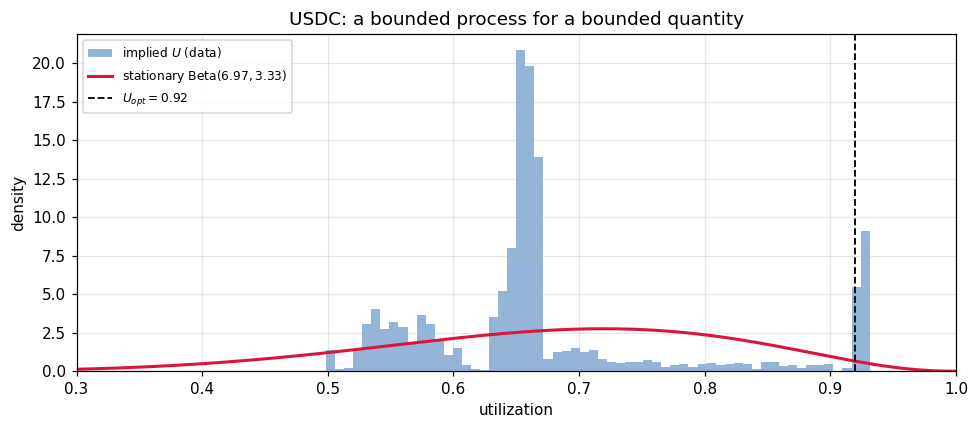


Regime occupancy (the inputs Part XI needs):
n_obs               3,361.0000
u_opt                   0.9200
u_mean                  0.6762
u_p95                   0.9277
u_max                   0.9313
frac_stressed           0.1044
r_b_mean_normal         0.0387
r_b_mean_stressed       0.1034
r_b_max                 0.1400
r_s_mean_normal         0.0228
r_s_mean_stressed       0.0863
r_s_max                 0.1173
convexity_ratio         3.7836


In [15]:
# --- Part IX: the broken CIR fits, then the Jacobi replacement -----------
cir = pd.read_csv(ROOT / "results" / "cir_usdc_weth_aave_v3.csv")
jcir = pd.read_csv(ROOT / "results" / "jcir_usdc_weth_aave_v3.csv")
print("The fits this module replaces -- CIR:\n")
print(cir[["series", "e_kappa", "e_theta", "e_sigma",
           "m_kappa", "m_theta", "m_sigma"]].to_string(index=False))
print("\n  theta = 4.98 is a long-run INTEREST RATE of 498%/yr;  m_theta = 2.0000 exactly")
print("  is the optimiser bound, not an estimate.")
print("\nand CIR-with-jumps (JCIR):\n")
print(jcir.to_string(index=False))
for _, r in jcir.iterrows():
    lhs, rhs = 2 * r["kappa"] * r["theta"], r["sigma"] ** 2
    print(f"  {r['series']:>12}: Feller 2*kappa*theta = {lhs:7.2f}  vs  sigma^2 = {rhs:7.2f}"
          f"   -> {'OK' if lhs >= rhs else 'VIOLATED (the process can reach 0)'}")

sym = "USDC"
cv = published_curve(configs, sym)
f = panel[sym].loc[CFG.window_start:CFG.window_end]
u_imp = implied_utilization(cv, f["borrower_variable_apr"].values / 100.0)
jac = fit_jacobi(u_imp, dt_years=1.0 / (365 * 24))
lo, hi = jac.boundaries_unattainable
m, v = jac.stationary_moments
print(f"\nJacobi fit to curve-implied USDC utilization:")
print(f"  kappa = {jac.kappa:.3f}/yr  (half-life {math.log(2)/jac.kappa*365*24:.1f} h)")
print(f"  theta = {jac.theta:.4f},  sigma = {jac.sigma:.4f}")
print(f"  boundary 0 unattainable: {lo}   (2*kappa*theta = "
      f"{2*jac.kappa*jac.theta:.2f}  vs  sigma^2 = {jac.sigma**2:.2f})")
print(f"  boundary 1 unattainable: {hi}   (2*kappa*(1-theta) = "
      f"{2*jac.kappa*(1-jac.theta):.2f}  vs  sigma^2 = {jac.sigma**2:.2f})")
print(f"  stationary Beta: mean {m:.4f}, sd {math.sqrt(v):.4f}   "
      f"(sample mean {u_imp.mean():.4f}, sd {u_imp.std():.4f})")
print("\n  Note the half-life is a few hours here TOO. That is a property of hourly")
print("  utilization data, not of the CIR misspecification -- see the caveat in IX.2.")
print("  What distinguishes this fit is that it passes the checks CIR fails: both")
print("  boundaries unattainable, theta a genuine number in [0,1], and a stationary")
print("  law that reproduces the sample.")

from scipy import stats as _st
a = 2 * jac.kappa * jac.theta / jac.sigma**2
bb = 2 * jac.kappa * (1 - jac.theta) / jac.sigma**2
grid_u = np.linspace(0.001, 0.999, 500)
fig, ax = plt.subplots()
ax.hist(u_imp, bins=60, density=True, alpha=0.5, color="#2b6cb0", label="implied $U$ (data)")
ax.plot(grid_u, _st.beta(a, bb).pdf(grid_u), lw=2, color="crimson",
        label=fr"stationary Beta$({a:.2f},{bb:.2f})$")
ax.axvline(cv.u_opt, color="k", ls="--", lw=1.2, label=fr"$U_{{opt}}={cv.u_opt}$")
ax.set_xlim(0.3, 1.0); ax.set_xlabel("utilization"); ax.set_ylabel("density")
ax.set_title(f"{sym}: a bounded process for a bounded quantity")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

print(f"\nRegime occupancy (the inputs Part XI needs):")
print(regime_summary(u_imp, cv, reserve_factor=float(configs.loc[sym, "reserveFactor"]))
      .to_string())

---
# Part X. Addition #7 --- liquidation recovery $R_\tau$

**What changed.** Two new modules, `optimal_long_short/recovery.py` (continuous crossing) and
`optimal_long_short/overshoot_recovery.py` (exact jump overshoot), a new paper section (§7), and a
validation job `jobs/validate_recovery.py`. This repairs the killed-payoff convention of §III.1.

## X.1 The problem

The base payoff is $\Pi_T=(n_1S_{1,T}-n_2S_{2,T})\mathbf 1_{\{\tau>T\}}$: liquidated paths get
**zero**. That is not what happens. A liquidation repays your debt and takes some collateral;
what is left over is still yours. So true terminal wealth is

$$\boxed{\;W_T \;=\; \underbrace{\Pi_T}_{\text{if you survive}} \;+\; \underbrace{R_\tau\mathbf 1_{\{\tau\le T\}}}_{\text{if you are liquidated}}\;}$$

and the base paper computed only the first term. Note that all the ingredients were already in
the repository: the liquidation bonus $\lambda$ is stored in every calibration JSON and was
used by nothing.

## X.2 Deriving $R_\tau$ from the protocol's own rules

The rule: a liquidator repays some of your debt and, in exchange, seizes collateral worth
$(1+\lambda)$ times what they repaid. $\lambda$ is the **liquidation bonus** --- the incentive
that makes someone bother. On Aave v3 Ethereum: $0.05$ for WETH, $0.045$ for the major
stablecoins, $0.05$--$0.075$ for wrapped BTC.

Take the full-repayment case. The liquidator pays off $V_{2,\tau}$ of debt and seizes
$(1+\lambda)V_{2,\tau}$ of collateral. You are left with

$$R_\tau \;=\; V_{1,\tau} \;-\; (1+\lambda)V_{2,\tau}.$$

Now use the definition of $\tau$. At the moment of a **continuous** crossing, the health factor
equals exactly one:

$$H_\tau = \frac{b\,V_{1,\tau}}{V_{2,\tau}} = 1
\qquad\Longrightarrow\qquad V_{1,\tau} = \frac{V_{2,\tau}}{b}.$$

Substituting,

$$R_\tau = \frac{V_{2,\tau}}{b}-(1+\lambda)V_{2,\tau}
\qquad\Longrightarrow\qquad
\boxed{\;R_\tau \;=\; V_{2,\tau}\,\frac{1-b(1+\lambda)}{b}\;}$$

*When is this positive?* Exactly when $b(1+\lambda)<1$, i.e.

$$\lambda \;<\; \frac1b-1 \;=\; \frac{1}{0.78}-1 \;=\; 0.282 .$$

Aave's $\lambda=0.05$ is far below that, so a liquidated borrower does keep something --- the
haircut $b$ leaves more collateral than the bonus takes away.

**Why express $R_\tau$ through the *debt* leg?** This is the clever step. We could equally have
written $R_\tau$ in terms of $V_{1,\tau}$. But writing it through $V_{2,\tau}$ makes $R_\tau$
proportional to $e^{X_{2,\tau}}$ --- and $X_2$ is the leg the machinery **already** tilts by
when it computes killed moments. Recovery therefore reuses the existing barrier system instead
of needing a new one.

**Per unit of equity.** Using $n_2S_{2,0}=b/(e^{h_0}-b)$ from §III.2,

$$R_\tau \;=\; \frac{1-b(1+\lambda)}{b}\cdot\frac{b}{e^{h_0}-b}\cdot e^{X_{2,\tau}}
\;=\; \underbrace{\frac{1-b(1+\lambda)}{e^{h_0}-b}}_{\text{recovery scale}}\;e^{X_{2,\tau}} .$$

The scale **grows as the buffer shrinks**, because a thinner buffer means a bigger book per
dollar of equity. Recovery matters most precisely where liquidation is likely.

## X.3 The honest caveat

The step $H_\tau=1$ assumed the barrier is crossed *continuously*. But $Z$ has jumps: a
downward jump can carry $H$ strictly below $1$ before anyone reacts, leaving $V_2 > bV_1$ and
**less** recovery than the formula gives --- possibly negative, which is **bad debt** (the
protocol eats a loss).

So the continuous-crossing recovery is an **upper bound**, and results built on it are
optimistic about liquidation.

**The exact version.** Drop the step $H_\tau=1$ and keep the actual leg values wherever the process
lands. Per unit of equity,

$$R_\tau \;=\; A\,e^{X_{1,\tau}} - B\,e^{X_{2,\tau}},\qquad A=\frac{H_0}{H_0-b},\quad
B=\frac{(1+\lambda)\,b}{H_0-b},$$

so its first two moments are combinations of the **joint hitting moments**
$\mathbb E[e^{a_1X_{1,\tau}+a_2X_{2,\tau}}\mathbf 1_{\{\tau\le T\}}]$ for
$(a_1,a_2)\in\{(1,0),(0,1),(2,0),(1,1),(0,2)\}$. Each one is the transform (FP) derived below,
with the tilt $e^{kX_2}$ replaced by the **bivariate** tilt $e^{a_1X_1+a_2X_2}$ --- the phase rates
shift by $a_1$ and $a_2$, and the barrier system is still $3\times3$. The tilted first-passage law
already integrates over where the process lands, so the overshoot is captured exactly without ever
writing down its density. This is `overshoot_recovery.exact_wealth_moments`, and the cell after
the derivation compares the two versions.

## X.4 The first-passage transform, derived

We need, for $k=1$ (to get the mean) and $k=2$ (to get the variance),

$$\mathbb E\!\left[e^{kX_{2,\tau}}\mathbf 1_{\{\tau\le T\}}\right].$$

This is hard because it couples *when* you were liquidated with *where the price was* then.
Three steps untangle it.

**Step 1 --- an exponential martingale.** Set $\alpha_k := \Psi(0,-ik) = \log\mathbb E[e^{kX_{2,1}}]$,
the per-unit-time growth rate of $e^{kX_2}$ (§II.6). Then

$$M_t \;=\; \exp\!\big(kX_{2,t}-\alpha_k t\big)$$

satisfies $\mathbb E[M_t]=1$ for every $t$ and is a **martingale**: $\mathbb E[M_t\mid\mathcal F_s]=M_s$.
(The definition of $\alpha_k$ is exactly what normalises the growth away.)

**Step 2 --- change of measure.** A positive martingale with mean one is a valid
change-of-probability density. Define a new probability $\mathbb P^{(k)}$ by
$\frac{d\mathbb P^{(k)}}{d\mathbb P}\big|_{\mathcal F_t} = M_t$. This is the **Esscher
transform**: it re-weights paths in proportion to $e^{kX_2}$, so under $\mathbb P^{(k)}$ the
process $X_2$ has a *tilted* drift and tilted jump rates --- and nothing else. Since $\tau$ is
a stopping time the identity extends to $\mathcal F_\tau$, giving

$$\mathbb E\!\left[e^{kX_{2,\tau}}\mathbf 1_{\{\tau\le T\}}\right]
= \mathbb E\!\left[M_\tau e^{\alpha_k\tau}\mathbf 1_{\{\tau\le T\}}\right]
= \mathbb E^{(k)}\!\left[e^{\alpha_k\tau}\mathbf 1_{\{\tau\le T\}}\right].$$

**The price has vanished.** What is left depends on $\tau$ alone.

**Step 3 --- Laplace transform in $T$.** Write $F(T)$ for the right-hand side and transform,
swapping the order of integration (Fubini):

$$\widehat F(q)=\int_0^\infty\! e^{-qT}\,\mathbb E^{(k)}\!\left[e^{\alpha_k\tau}\mathbf 1_{\{\tau\le T\}}\right]dT
= \mathbb E^{(k)}\!\left[e^{\alpha_k\tau}\int_\tau^\infty e^{-qT}dT\right]
= \frac1q\,\mathbb E^{(k)}\!\left[e^{-(q-\alpha_k)\tau}\right].$$

(The inner integral is elementary: $\int_\tau^\infty e^{-qT}dT=e^{-q\tau}/q$.)

Now connect $\mathbb E[e^{-s\tau}]$ to the **survival** function we already know how to compute.
For any non-negative random variable, integration by parts gives

$$\int_0^\infty e^{-st}\,\mathbb P(\tau>t)\,dt \;=\; \frac{1-\mathbb E[e^{-s\tau}]}{s}
\qquad\Longleftrightarrow\qquad
\mathbb E[e^{-s\tau}] \;=\; 1-s\,\widehat p_{\mathrm{surv}}(s).$$

Substituting with $s=q-\alpha_k$:

$$\boxed{\;\widehat F(q)\;=\;\frac1q\Big(1-(q-\alpha_k)\,\widehat p^{\,(k)}_{\mathrm{surv}}(q-\alpha_k)\Big)\;}
\tag{FP}$$

where $\widehat p^{\,(k)}_{\mathrm{surv}}$ is **the survival transform you already have**,
evaluated under the $k$-tilted dynamics and at a shifted argument.

**The cost of recovery is therefore: one extra Laplace inversion per moment order.** No new
linear algebra --- still the same $3\times3$ barrier system.

*Convergence.* For real $q$ the identity needs $q>\alpha_k$, so that $q-\alpha_k$ sits to the
right of the abscissa of convergence; the code checks this and raises otherwise. For complex
$q$ --- which is what Talbot actually uses --- the contour goes into the left half-plane and the
formula holds by **analytic continuation**: both sides are analytic, they agree on an interval,
so they agree everywhere they are defined.

## X.5 Combining the two pieces

$\Pi_T$ lives on $\{\tau>T\}$ and $R_\tau\mathbf 1$ on $\{\tau\le T\}$. These events are
**disjoint and exhaustive**, so the product $\Pi_T\cdot R_\tau\mathbf 1$ is identically zero and
the cross term in $(x+y)^2$ vanishes:

$$\mathbb E[W_T]=\mathbb E[\Pi_T]+\mathbb E[R_\tau\mathbf 1],
\qquad
\mathbb E[W_T^2]=\mathbb E[\Pi_T^2]+\mathbb E[R_\tau^2\mathbf 1].$$

Then $\operatorname{Var}(W_T)=\mathbb E[W_T^2]-\mathbb E[W_T]^2$ as usual.

## X.6 Two free consistency checks

Good numerical work checks itself where it can do so for free. Two such checks fall out:

1. **Set $k=0$ in (FP).** The integrand $e^{0\cdot X_2}$ is $1$, so the transform must return
   $\mathbb P(\tau\le T)=1-p_{\mathrm{surv}}$ --- computed by a completely different route. They
   agree to $\sim\!10^{-11}$.
2. **Check $\Psi(0,-i)=\mu_2$.** At $k=1$ the tilt exponent is by definition
   $\log\mathbb E[e^{X_2}]$ per unit time, which §II.5 pinned to $\mu_2$. If the compensator
   bookkeeping were wrong, this would fail.

In [16]:
# --- Part X: the two free consistency checks -----------------------------
from optimal_long_short.inversion import TalbotInverter
from optimal_long_short.recovery import (hitting_moment, recovery_coefficient,
                                         tilt_exponent, wealth_moments)
from optimal_long_short.overshoot_recovery import exact_wealth_moments

inv = TalbotInverter(M=32)

print("Check 2 -- the drift normalisation:")
print(f"  Psi(0,-i)   = {tilt_exponent(params, 1):.12f}")
print(f"  mu_2        = {params.mu2:.12f}")
print(f"  |difference| = {abs(tilt_exponent(params,1)-params.mu2):.3e}\n")

print("Check 1 -- (FP) at k = 0 must reproduce the liquidation probability:")
chk = []
for h0 in (0.10, 0.25, 0.50):
    ref = float(h0_liquidation_moment_report(params, [h0], b=B, T=T,
                                             max_moment_order=1)[0]["p_liq"])
    fp = hitting_moment(params, 0, h0, T, inv)
    chk.append({"h0": h0, "p_liq (survival resolvent)": ref,
                "p_liq via (FP)": fp, "abs err": abs(fp - ref)})
print(pd.DataFrame(chk).to_string(index=False,
      formatters={"abs err": lambda v: f"{v:.2e}"}))

Check 2 -- the drift normalisation:
  Psi(0,-i)   = -0.416786531605
  mu_2        = -0.416786531605
  |difference| = 0.000e+00

Check 1 -- (FP) at k = 0 must reproduce the liquidation probability:
    h0  p_liq (survival resolvent)  p_liq via (FP)  abs err
0.1000                      0.2455          0.2455 2.69e-11
0.2500                      0.0094          0.0094 2.44e-11
0.5000                      0.0000          0.0000 2.58e-11


liquidation bonus lambda = 0.05;  positive recovery requires lambda < 1/b - 1 = 0.2821  ->  True
recovery coefficient (1 - b(1+lambda))/b = 0.232051

    h0     H0  initial_leverage  p_liq  recovery_scale  mean_killed  mean_wealth  var_killed  var_wealth
0.0662 1.0685            3.7037 0.4170          0.6274       0.6687       0.9456      0.3425      0.0799
0.1503 1.1622            3.0407 0.0965          0.4736       0.9296       0.9817      0.1234      0.0521
0.2344 1.2642            2.6111 0.0140          0.3738       0.9800       0.9864      0.0426      0.0329
0.3185 1.3750            2.3109 0.0013          0.3042       0.9845       0.9850      0.0246      0.0237
0.4026 1.4956            2.0899 0.0001          0.2529       0.9832       0.9833      0.0187      0.0186
0.4866 1.6268            1.9211 0.0000          0.2137       0.9819       0.9819      0.0153      0.0153
0.5707 1.7695            1.7883 0.0000          0.1829       0.9808       0.9808      0.0131      0.0131
0.6548 1.9

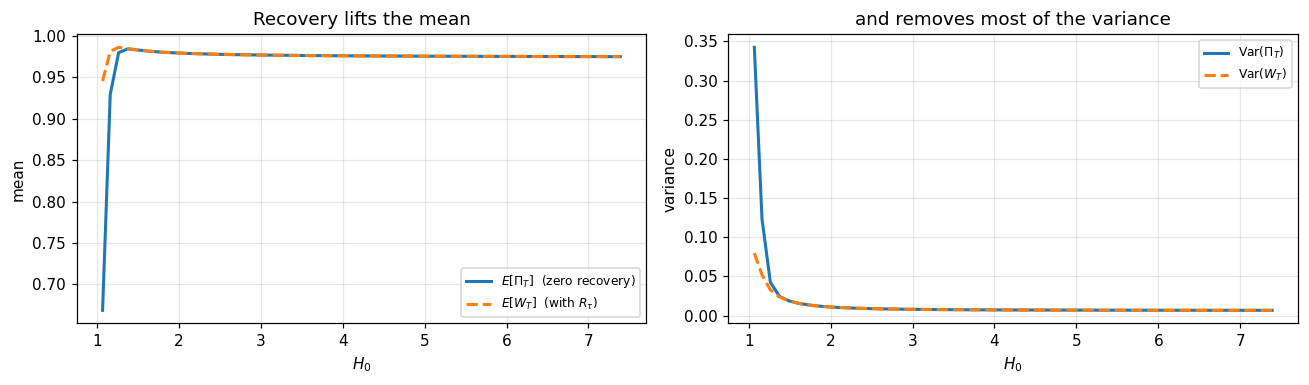


At H0 = 1.1618  (p_liq = 0.0971):   killed -> continuous crossing -> exact
  mean : 0.9292  ->  0.9816  ->  0.9798
  var  : 0.1240  ->  0.0522  ->  0.0539
  overshoot correction to mean recovery: -3.5%  (small, because the fitted jumps are sub-percent)

Why the variance collapses: the killed convention places a big atom of probability
exactly at 0 (total loss). Recovery moves that atom to a positive value, and an atom
far from the mean is what most of the variance was.


In [17]:
# --- Part X: how much does recovery change the answer? -------------------
lam_liq = market["liq_bonus"]
print(f"liquidation bonus lambda = {lam_liq};  positive recovery requires "
      f"lambda < 1/b - 1 = {1/B - 1:.4f}  ->  {lam_liq < 1/B - 1}")
print(f"recovery coefficient (1 - b(1+lambda))/b = {recovery_coefficient(B, lam_liq):.6f}\n")

wm = pd.DataFrame([wealth_moments(params, float(h0), b=B, liq_bonus=lam_liq, T=T, inverter=inv)
                   for h0 in np.linspace(h0_min, 2.0, 24)])
print(wm[["h0", "H0", "initial_leverage", "p_liq", "recovery_scale",
          "mean_killed", "mean_wealth", "var_killed", "var_wealth"]].head(8).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].plot(wm["H0"], wm["mean_killed"], lw=2, label=r"$E[\Pi_T]$  (zero recovery)")
axes[0].plot(wm["H0"], wm["mean_wealth"], lw=2, ls="--", label=r"$E[W_T]$  (with $R_\tau$)")
axes[0].set_ylabel("mean"); axes[0].set_title("Recovery lifts the mean")
axes[1].plot(wm["H0"], wm["var_killed"], lw=2, label=r"$\mathrm{Var}(\Pi_T)$")
axes[1].plot(wm["H0"], wm["var_wealth"], lw=2, ls="--", label=r"$\mathrm{Var}(W_T)$")
axes[1].set_ylabel("variance"); axes[1].set_title("and removes most of the variance")
for a in axes:
    a.set_xlabel(r"$H_0$"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

r = exact_wealth_moments(params, 0.15, b=B, liq_bonus=lam_liq, T=T, inverter=inv)
print(f"\nAt H0 = {r['H0']:.4f}  (p_liq = {r['p_liq']:.4f}):   killed -> continuous crossing -> exact")
print(f"  mean : {r['mean_killed']:.4f}  ->  {r['mean_wealth_cc']:.4f}  ->  {r['mean_wealth']:.4f}")
print(f"  var  : {r['var_killed']:.4f}  ->  {r['var_wealth_cc']:.4f}  ->  {r['var_wealth']:.4f}")
print(f"  overshoot correction to mean recovery: {r['E_recovery'] / r['E_recovery_cc'] - 1:+.1%}"
      "  (small, because the fitted jumps are sub-percent)")
print("\nWhy the variance collapses: the killed convention places a big atom of probability")
print("exactly at 0 (total loss). Recovery moves that atom to a positive value, and an atom")
print("far from the mean is what most of the variance was.")

---
# Part XI. Addition #8 --- regime-switching carry and the $6\times6$ resolvent

**What changed.** A new module `optimal_long_short/regime_switching.py`, a new paper
proposition and lemma, and a validation job `jobs/validate_regime_switching.py`. This is the
largest piece of new mathematics in the batch.

## XI.1 Why a constant carry was the wrong object

Part VII showed deterministic carry is worth at most a few percent of one barrier standard
deviation on volatile pairs. Part IX showed why that is not the end of the story: the borrow
rate is **convex in utilization**, with a slope that multiplies by a factor of $25$--$125$ at
the kink. Published $s_2$ is $0.60$--$3.00$ against $s_1$ of $0.027$--$0.055$.

So a debt leg that normally costs $2.5\%$ can cost *tens of percent* while the pool is
stressed. And the stressed state is not random noise --- it is the **deleveraging state**, the
same state in which the price ratio $Z$ moves violently. Averaging over it destroys exactly the
dependence that matters.

The fix: **let the carry be a two-state process instead of a constant.**

## XI.2 A continuous-time Markov chain, from zero

Let $J_t\in\{1,2\}$ be the regime at time $t$: state $1$ = normal, state $2$ = stressed.

*The rule.* From state $1$ you wait an $\mathrm{Exp}(q_1)$ amount of time (mean $1/q_1$) and
then flip to state $2$; from state $2$ you wait $\mathrm{Exp}(q_2)$ and flip back. The waiting
times are exponential for the same memorylessness reason as in §II.4: the future does not
depend on how long you have already been in the current state.

*The generator.* All of that is encoded in the matrix

$$Q=\begin{pmatrix}-q_1 & q_1\\ q_2 & -q_2\end{pmatrix},$$

whose off-diagonal entries are the switching rates and whose rows sum to zero (probability is
conserved). It is called the **generator** because the law of the chain solves
$\frac{d}{dt}p(t)^\top = p(t)^\top Q$.

*The stationary distribution.* The long-run fractions $\pi=(\pi_1,\pi_2)$ solve $\pi^\top Q=0$
with $\pi_1+\pi_2=1$. The first component gives $-q_1\pi_1+q_2\pi_2=0$, i.e.
$\pi_1 q_1 = \pi_2 q_2$ ("flow out of 1 = flow out of 2"), so

$$\boxed{\;\pi_1=\frac{q_2}{q_1+q_2},\qquad \pi_2=\frac{q_1}{q_1+q_2}\;}$$

*Calibrating it.* Two numbers are directly readable from the utilization series of Part IX:

* the **occupation fraction** $\pi_2$ = the share of hours with $U>U_{\mathrm{opt}}$;
* the **mean stress duration** = $1/q_2$ (the expected length of one $\mathrm{Exp}(q_2)$ wait).

Inverting: $q_2 = 1/\text{duration}$, and from $\pi_2=q_1/(q_1+q_2)$,

$$q_1 \;=\; q_2\,\frac{\pi_2}{1-\pi_2}.$$

That is `RegimeSpec.from_occupation`, and it is why the module asks for those two quantities
rather than for $q_1,q_2$ directly.

## XI.3 What switches, and what does not

Let $c_i$ be the net carry in state $i$. Typically $c_1$ is small and slightly negative, while
$c_2$ is *large* and negative, because stress means the borrow rate has climbed the steep
segment.

By Part VI, carry enters as a drift shift, so the Lévy exponent of $Z$ in state $i$ is

$$\boxed{\;\psi^i(s)\;=\;\psi_Z^{(k)}(s)\;+\;c_i\,s\;}$$

**Only the linear term changes.** Diffusion, jump intensities, jump sizes, the phase rates
$r_{1,-},r_{2,-}$, and the admissibility bounds $k\eta_{1,+}<1$, $k\eta_{2,+}<1$ are all shared
between the two states. This is Part VI applied state by state, and it is the whole reason the
extension stays cheap.

## XI.4 The coupled equations

Write $\widehat U^i(q,x)$ for the Laplace-transformed killed moment *started in state $i$* at
distance $x$. In state $1$ two things can happen in the next instant: the process moves (giving
the generator $\mathcal L^1$), or the regime flips to $2$ at rate $q_1$. Accounting for both:

$$\begin{aligned}
(q+q_1-\mathcal L^{1})\,\widehat U^{1} \;-\; q_1\,\widehat U^{2} &= G_k,\\
-\,q_2\,\widehat U^{1} \;+\; (q+q_2-\mathcal L^{2})\,\widehat U^{2} &= G_k .
\end{aligned}$$

Read the first line: the $+q_1$ on the diagonal is the rate at which you *leave* state 1; the
$-q_1\widehat U^2$ is the value you get when you *arrive* in state 2. Two equations, two
unknown functions --- **a system**, where the base model had a single equation.

## XI.5 Where the six roots come from

Try the same exponential ansatz as in §III.5, but now vector-valued:

$$\begin{pmatrix}\widehat U^1\\ \widehat U^2\end{pmatrix}
\;=\; B\,v(\gamma)\,e^{\gamma x}, \qquad v(\gamma)\in\mathbb C^2 .$$

Applying $\mathcal L^i$ to $e^{\gamma x}$ returns $\psi^i(\gamma)e^{\gamma x}$, so the
homogeneous system becomes $A(\gamma)\,v = 0$ with

$$A(\gamma)=\begin{pmatrix} q+q_1-\psi^1(\gamma) & -q_1\\[2pt] -q_2 & q+q_2-\psi^2(\gamma)\end{pmatrix}.$$

A non-zero $v$ exists **iff** the matrix is singular, i.e. its determinant vanishes:

$$\boxed{\;\Delta(\gamma)\;=\;\big(q+q_1-\psi^1(\gamma)\big)\big(q+q_2-\psi^2(\gamma)\big)-q_1q_2\;=\;0\;}$$

This is the **regime characteristic equation**. Compare with the base model's $\psi(\gamma)=q$:
a product of two such factors, minus a coupling term.

**Counting the roots.** $\psi^1$ and $\psi^2$ share the same four poles (§II.6), so write both
over a common denominator, $\psi^i=N^i/D$, with $\deg D=4$ and $\deg N^i=6$. Multiply $\Delta$
by $D^2$ to clear denominators:

$$\Delta(s)D(s)^2 \;=\; \widetilde N^1(s)\,\widetilde N^2(s)\;-\;q_1q_2\,D(s)^2,
\qquad \widetilde N^i := (q+q_i)D-N^i .$$

Each $\widetilde N^i$ has degree $6$, so their product has degree $12$; the subtracted term has
degree $8$. **Degree $12$: twelve roots, of which six have negative real part.** In the base
model it was degree $6$ with three decaying roots. Everything has exactly doubled.

## XI.6 Six roots need six boundary conditions --- and there are exactly six

The count must match or the system is unsolvable. Redo §III.5 **per state**:

* **absorption**, $\widehat U^i(q,\text{barrier})=0$, one per state: **2 conditions**;
* **downward-phase cancellation** for each of $r_{1,-},r_{2,-}$, in each state: **4 conditions**.

Total: **6**, matching the six unknown coefficients $B_1,\dots,B_6$. The barrier system is
$\mathbf M_{\mathrm{bar}}B = \text{rhs}$ with $\mathbf M_{\mathrm{bar}}\in\mathbb C^{6\times6}$.

*Why the coupling adds no extra conditions.* The phase-cancellation conditions exist because
extending the solution by zero below the barrier leaves a residual **through the jump integral**
inside $\mathcal L^i$. The coupling terms $-q_i\widehat U^j$ are plain multiplication --- no
generator, no integral, no residual. So each equation contributes the same three conditions it
did in the single-regime case, and no more.

## XI.7 Three checks the construction must pass, and does

**(a) Decoupled limit.** Setting $q_1=q_2=0$ removes the coupling, and $\Delta$ factorises into
$(q-\psi^1)(q-\psi^2)$: two independent copies of the base problem. The $6\times6$ system must
collapse into two $3\times3$ systems and reproduce each state's single-regime answer. It does,
to $\sim\!10^{-15}$.

**(b) Constant-carry limit.** Set $c_1=c_2$ but keep $q_1\neq q_2$: the coupling is *active* but
economically irrelevant, since both states have the same carry. The answer must equal the
single-regime answer. It does, to $\sim\!10^{-14}$ for $k=0,1,2$. This is the stronger of the
two tests: it exercises all the new code paths and still has a known answer.

**(c) Monte Carlo** with switching genuinely active, agreeing once the time-discretisation bias
is refined away (residual $+0.0113$ at $10^3$ steps, $+0.0004$ at $4\times10^3$).

## XI.8 Two implementation details worth understanding

**The eigenvector comes from the adjugate.** Given singular $A$, the kernel vector could be
written in closed form, e.g. $v=(q_1,\,q+q_1-\psi^1)^\top$. But that formula degenerates when
$q_1=0$. Instead take a column of the **adjugate**

$$\operatorname{adj}(A)=\begin{pmatrix}A_{22} & -A_{12}\\ -A_{21} & A_{11}\end{pmatrix},
\qquad A\cdot\operatorname{adj}(A)=\det(A)\,I = 0 \ \text{ when } \det A=0,$$

so **every column of the adjugate is in the kernel**. The code takes whichever column has the
larger norm. In the decoupled limit one column vanishes identically and the other correctly
identifies which state the root belongs to --- the degenerate case handles itself.

**Non-resonance generalises.** The particular solution needs $A(j)$ invertible for the forcing
exponents $j=0,\dots,k$. Since $\det A(j)=\Delta(j)$, the base model's condition
$q\neq\psi(j)$ becomes $\Delta(j)\neq0$, and the code raises a clear error if it is hit.

**Invertibility of $\mathbf M_{\mathrm{bar}}$.** The argument is honest about being generic:
$\det\mathbf M_{\mathrm{bar}}$ is *analytic* in $(q_1,q_2)$, and at $q_1=q_2=0$ it factorises
into the product of the two single-regime determinants, each non-zero. A non-vanishing analytic
function can only vanish on a set of measure zero, so the system is invertible for all switching
rates **except possibly a null set**. That is weaker than a pointwise theorem, and the paper
says so; `RegimeResolvent.condition_number` is the numerical check.

## XI.9 What it buys

A deterministic model can only use the stationary mean carry $\pi_1c_1+\pi_2c_2$ --- one number,
one answer. The regime model answers a question the deterministic one cannot even ask:
**does it matter which regime you open the position in?**

It *can*. With an illustrative stressed carry of $-60\%$ on a textbook parameter set, the
difference in survival between opening normal and opening stressed reaches **ten percentage
points** over three months (the last cell of this Part). Calibrated to the WETH debt leg of the
benchmark book, it does **not**: over a month the opening regime moves survival by at most
$0.09$ pp, because stressed spells last days and a $4\%$ stressed rate barely moves the drift
(paper Table 13; the final cell reads it). The economic reading is that the rate channel matters
through its **tail, not its mean**: a debt leg that never approaches its kink has no rate channel
at all. Wrapped BTC sits at $U\approx0.03$--$0.05$ against
$U_{\mathrm{opt}}=0.45$ and spends $0.0\%$ of hours stressed --- a BTC debt leg switches the
mechanism off by construction. WETH, USDC, USDT and USDe spend $5\%$--$14\%$ of hours above
their kinks, and are where the extension bites.

In [18]:
# --- Part XI: build the regime spec from the data ------------------------
from optimal_long_short.kou_model import KouZTiltedDynamics
from optimal_long_short.regime_switching import (RegimeResolvent, RegimeRootFinder,
                                                 RegimeSpec, RegimeSwitchingDynamics)

cv_weth = published_curve(configs, "WETH")
f_weth = panel["WETH"].loc[CFG.window_start:CFG.window_end]
u_weth = implied_utilization(cv_weth, f_weth["borrower_variable_apr"].values / 100.0)
stressed = u_weth > cv_weth.u_opt

# mean duration of a stress episode, in years (runs of consecutive stressed hours)
runs, cur = [], 0
for s in stressed:
    if s:
        cur += 1
    elif cur:
        runs.append(cur); cur = 0
if cur:
    runs.append(cur)
mean_dur_yr = float(np.mean(runs)) / (365 * 24)

spec_rs = RegimeSpec.from_occupation(
    frac_stressed=float(stressed.mean()),
    mean_duration_stressed=mean_dur_yr,
    # net carry per regime.  The collateral here is WBTC, whose supply rate is ~0.01%,
    # so c_i = r_s - r_b is essentially -r_b in each regime; we set c_i = -r_b outright.
    c_normal=-float(np.mean(np.array([cv_weth.borrow_rate(x) for x in u_weth])[~stressed])),
    c_stressed=-float(np.mean(np.array([cv_weth.borrow_rate(x) for x in u_weth])[stressed])),
)
print(f"WETH as the debt leg, window {CFG.window_start.date()} -> {CFG.window_end.date()}")
print(f"  fraction of hours above U_opt = {stressed.mean():.4f}")
print(f"  mean stress episode           = {np.mean(runs):.1f} hours ({mean_dur_yr:.5f} yr)")
print(f"  q1 = {spec_rs.q1:.3f}/yr, q2 = {spec_rs.q2:.3f}/yr")
print(f"  stationary (normal, stressed) = ({spec_rs.stationary[0]:.4f}, "
      f"{spec_rs.stationary[1]:.4f})   [check: q1/(q1+q2) = "
      f"{spec_rs.q1/(spec_rs.q1+spec_rs.q2):.4f}]")
print(f"  carry: c1 = {spec_rs.c1:+.4f}, c2 = {spec_rs.c2:+.4f}")
print(f"  stationary mean carry = {spec_rs.mean_carry:+.4f}  <-- all a deterministic model sees")

WETH as the debt leg, window 2026-03-17 -> 2026-08-04
  fraction of hours above U_opt = 0.1357
  mean stress episode           = 456.0 hours (0.05205 yr)
  q1 = 3.015/yr, q2 = 19.211/yr
  stationary (normal, stressed) = (0.8643, 0.1357)   [check: q1/(q1+q2) = 0.1357]
  carry: c1 = -0.0214, c2 = -0.0488
  stationary mean carry = -0.0251  <-- all a deterministic model sees


single regime: characteristic polynomial degree  6  ->  6 roots, 3 decaying (a 3x3 system)
two regimes  : characteristic polynomial degree 12  ->  12 roots, 6 decaying (a 6x6 system)



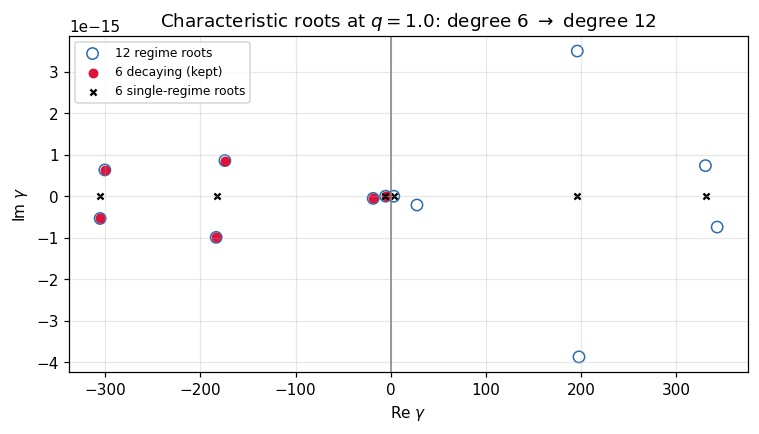

Condition number of the 6x6 barrier matrix (the numerical invertibility check):
  q =    0.1  ->  cond(M_bar) =     11.3
  q =    1.0  ->  cond(M_bar) =     11.5
  q =   10.0  ->  cond(M_bar) =     12.2
  q =  100.0  ->  cond(M_bar) =     11.9


In [19]:
# --- Part XI: twelve roots where the base model had six ------------------
from optimal_long_short.root_finder import CharacteristicRootFinder

BENCH_SPEC = RegimeSpec(q1=2.0, q2=25.0, c1=0.02, c2=-0.60)  # the paper's illustration
base_dyn = KouZTiltedDynamics(params=params, k=0)
dyn_rs = RegimeSwitchingDynamics(base=base_dyn, spec=BENCH_SPEC)
q_test = 1.0

poly12 = RegimeRootFinder(dyn_rs).polynomial(q_test)
roots12 = np.roots(poly12)
roots6 = np.roots(CharacteristicRootFinder(base_dyn)._build_polynomial(q_test))
decaying = RegimeRootFinder(dyn_rs).find(q_test)

poly6 = CharacteristicRootFinder(base_dyn)._build_polynomial(q_test)
print(f"single regime: characteristic polynomial degree {len(np.trim_zeros(poly6, 'f'))-1:>2}"
      f"  ->  {len(roots6)} roots, {int((roots6.real < 0).sum())} decaying (a 3x3 system)")
print(f"two regimes  : characteristic polynomial degree {len(np.trim_zeros(poly12, 'f'))-1:>2}"
      f"  ->  {len(roots12)} roots, {len(decaying)} decaying (a 6x6 system)\n")

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.scatter(roots12.real, roots12.imag, s=55, facecolors="none", edgecolors="#2b6cb0",
           label="12 regime roots")
ax.scatter([g.real for g in decaying], [g.imag for g in decaying], s=30, color="crimson",
           label="6 decaying (kept)")
ax.scatter(roots6.real, roots6.imag, s=16, marker="x", color="black",
           label="6 single-regime roots")
ax.axvline(0, color="grey", lw=1)
ax.set_xlabel(r"Re $\gamma$"); ax.set_ylabel(r"Im $\gamma$")
ax.set_title(fr"Characteristic roots at $q={q_test}$: degree 6 $\to$ degree 12")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

print("Condition number of the 6x6 barrier matrix (the numerical invertibility check):")
for q in (0.1, 1.0, 10.0, 100.0):
    print(f"  q = {q:6.1f}  ->  cond(M_bar) = "
          f"{RegimeResolvent(dyn_rs, h0=0.25, b=B).condition_number(q):8.1f}")

In [20]:
# --- Part XI: check (b), the constant-carry limit ------------------------
from optimal_long_short.drift import with_price_drift_view
from optimal_long_short.laplace_resolvent import (GeneralSolution, HomogeneousSolution,
                                                  ParticularSolution)
from optimal_long_short.market_params import MarketParams
from optimal_long_short.model_params import KouParams
from optimal_long_short.strategy import UnitExposureLongShortStrategy

BENCH = KouParams(mu1=0.05, sigma1=0.20, lam1=1.0, p1=0.5, eta1_pos=0.10, eta1_neg=0.125,
                  mu2=0.03, sigma2=0.15, lam2=0.8, p2=0.5, eta2_pos=1/12, eta2_neg=1/9,
                  rho=0.3)   # the textbook benchmark used by jobs/validate_regime_switching.py

def single_regime(p, k, q, h0, T_):
    strat = UnitExposureLongShortStrategy(h0=h0, market=MarketParams(b=B, S10=1.0, S20=1.0), T=T_)
    return GeneralSolution(HomogeneousSolution(
        ParticularSolution(KouZTiltedDynamics(params=p, k=k), strat))).evaluate_at_origin(q)

Q_, H0_ = 0.9, 0.30
rows = []
for k in (0, 1, 2):
    for c in (0.0, 0.05):
        ref = single_regime(with_price_drift_view(BENCH, delta_mu1=c), k, Q_, H0_, 1/12)
        got = RegimeResolvent(RegimeSwitchingDynamics(
            base=KouZTiltedDynamics(params=BENCH, k=k),
            spec=RegimeSpec(q1=3.0, q2=7.0, c1=c, c2=c)), h0=H0_, b=B).transform(Q_)
        rows.append({"k": k, "c1=c2": c, "single regime": ref.real,
                     "6x6 state 1": got[0].real, "6x6 state 2": got[1].real,
                     "max rel err": max(abs(got[0]-ref), abs(got[1]-ref))/abs(ref)})
print("Check (b): c1 = c2 with q1 != q2 -- coupling active, answer must be the single-regime one\n")
print(pd.DataFrame(rows).to_string(index=False,
      formatters={"max rel err": lambda v: f"{v:.2e}"}))

# check (a): the decoupled limit
rows = []
for c1, c2 in [(0.0, 0.10), (-0.20, 0.05)]:
    r1 = single_regime(with_price_drift_view(BENCH, delta_mu1=c1), 0, Q_, H0_, 1/12)
    r2 = single_regime(with_price_drift_view(BENCH, delta_mu1=c2), 0, Q_, H0_, 1/12)
    got = RegimeResolvent(RegimeSwitchingDynamics(
        base=KouZTiltedDynamics(params=BENCH, k=0),
        spec=RegimeSpec(q1=0.0, q2=0.0, c1=c1, c2=c2)), h0=H0_, b=B).transform(Q_)
    rows.append({"c1": c1, "c2": c2, "err state 1": abs(got[0]-r1)/abs(r1),
                 "err state 2": abs(got[1]-r2)/abs(r2)})
print("\nCheck (a): q1 = q2 = 0 must reproduce two independent single-regime problems\n")
print(pd.DataFrame(rows).to_string(index=False,
      formatters={"err state 1": lambda v: f"{v:.2e}", "err state 2": lambda v: f"{v:.2e}"}))

Check (b): c1 = c2 with q1 != q2 -- coupling active, answer must be the single-regime one

 k  c1=c2  single regime  6x6 state 1  6x6 state 2 max rel err
 0 0.0000         0.8759       0.8759       0.8759    1.57e-14
 0 0.0500         0.9200       0.9200       0.9200    7.72e-15
 1 0.0000         0.6123       0.6123       0.6123    2.54e-15
 1 0.0500         0.7024       0.7024       0.7024    7.59e-15
 2 0.0000         0.5092       0.5092       0.5092    5.01e-15
 2 0.0500         0.6674       0.6674       0.6674    2.00e-15

Check (a): q1 = q2 = 0 must reproduce two independent single-regime problems

     c1     c2 err state 1 err state 2
 0.0000 0.1000    1.39e-15    6.95e-16
-0.2000 0.0500    1.22e-14    8.21e-15


In [21]:
# --- Part XI: what a deterministic model cannot say ----------------------
T_rs = 0.25
inv_rs = TalbotInverter(M=32)
rows = []
for h0 in (0.10, 0.25, 0.50):
    R = RegimeResolvent(RegimeSwitchingDynamics(
        base=KouZTiltedDynamics(params=BENCH, k=0), spec=BENCH_SPEC), h0=h0, b=B)
    p_n = float(inv_rs.invert(lambda q: R.transform(q)[0], T_rs))
    p_s = float(inv_rs.invert(lambda q: R.transform(q)[1], T_rs))
    p_stat = float(inv_rs.invert(R.transform_stationary, T_rs))
    rows.append({"h0": h0, "H0": math.exp(h0), "open normal": p_n, "open stressed": p_s,
                 "stationary mix": p_stat, "difference (pp)": 100 * (p_s - p_n)})
print(f"Survival probability by OPENING regime.  q1={BENCH_SPEC.q1}, q2={BENCH_SPEC.q2}, "
      f"c1={BENCH_SPEC.c1:+}, c2={BENCH_SPEC.c2:+}, T={T_rs}\n")
print(pd.DataFrame(rows).to_string(index=False))
print(f"\nStationary stressed fraction = {BENCH_SPEC.stationary[1]:.4f}")
print(f"Stationary mean carry        = {BENCH_SPEC.mean_carry:+.5f}")
print("A deterministic model using that mean returns ONE number and cannot produce the")
print("spread between the two columns. That is the illustrative spec; the calibrated one follows.")

Survival probability by OPENING regime.  q1=2.0, q2=25.0, c1=+0.02, c2=-0.6, T=0.25

    h0     H0  open normal  open stressed  stationary mix  difference (pp)
0.1000 1.1052       0.6065         0.5057          0.5990         -10.0834
0.2500 1.2840       0.9371         0.9143          0.9354          -2.2787
0.5000 1.6487       0.9935         0.9921          0.9934          -0.1395

Stationary stressed fraction = 0.0741
Stationary mean carry        = -0.02593
A deterministic model using that mean returns ONE number and cannot produce the
spread between the two columns. That is the illustrative spec; the calibrated one follows.


In [22]:
# --- Part XI: the same question on the CALIBRATED book (paper Table 13) ---
RC = json.load(open(ROOT / "results/merged/regime_calibrated.json"))  # benchmark drift
print(f"calibrated regimes (WETH debt, U_opt={RC['U_opt']}): q1={RC['q1']:.1f}, q2={RC['q2']:.1f} /yr, "
      f"c1={RC['c1']:+.2%}, c2={RC['c2']:+.2%}, T=1/12")
print(f"The paper thresholds the RAW utilization series ({RC['frac_stressed']:.1%} of hours stressed);")
print(f"spec_rs above thresholds the CURVE-IMPLIED series ({float(stressed.mean()):.1%} stressed, "
      f"q1={spec_rs.q1:.1f}, q2={spec_rs.q2:.1f}),")
print("which corrects the raw series' upward bias and would make the effect smaller still.\n")
tab = pd.DataFrame(RC["rows"]).set_index("h0")
print(tab[["p_price_only", "p_det_mean_carry", "p_open_normal", "p_open_stressed",
           "carry_level_pp", "open_diff_pp", "jensen_pp"]].round(4).to_string())
print("\nThe mean carry costs ~0.8 pp near the barrier; the opening regime and the convexity")
print("correction are one and two orders of magnitude smaller. Inert at a monthly horizon.")

calibrated regimes (WETH debt, U_opt=0.9): q1=16.3, q2=65.5 /yr, c1=-2.13%, c2=-4.03%, T=1/12
The paper thresholds the RAW utilization series (19.9% of hours stressed);
spec_rs above thresholds the CURVE-IMPLIED series (13.6% stressed, q1=3.0, q2=19.2),
which corrects the raw series' upward bias and would make the effect smaller still.

        p_price_only  p_det_mean_carry  p_open_normal  p_open_stressed  carry_level_pp  open_diff_pp  jensen_pp
h0                                                                                                             
0.1000        0.7600            0.7545         0.7546           0.7537         -0.5549       -0.0911    -0.0276
0.2500        0.9911            0.9906         0.9906           0.9906         -0.0433       -0.0057    -0.0018
0.5000        1.0000            1.0000         1.0000           1.0000         -0.0000       -0.0000    -0.0000

The mean carry costs ~0.8 pp near the barrier; the opening regime and the convexity
correction are o

---
# Part XII. Addition #9 --- the barbell: buying the convexities the levered book sells

**What changed.** A new module `optimal_long_short/barbell.py`. This is the *constructive*
consequence of the two negative empirical findings.

## XII.1 The diagnosis

Put Part VII and Part IX together. The leveraged long--short book on Aave is short **two**
convexities and paid for neither:

1. **Short the barrier.** The payoff is killed at liquidation: a small, bounded upside against
   a rare near-total loss. That is the payoff profile of a *written option*.
2. **Short the utilization kink.** The borrower pays $r_b(U)$, whose slope multiplies by
   $25$--$125$ at $U_{\mathrm{opt}}$. Paying a piecewise-linear convex function of a random
   variable is being **short a call on utilization**, struck at $U_{\mathrm{opt}}$.

And Part VII showed the net carry is $-1.8\%$ to $-4.5\%$: the position **pays** to hold both
short-convexity exposures. That is the wrong side of both trades.

## XII.2 The barbell

A **barbell** puts most of the money in something very safe and a little in something very
convex, with nothing in the middle. Here:

* **The safe leg** ($90\%$): supply, with a buffer so deep that liquidation is negligible. In
  the framework this is the $h_0\to\infty$ limit where the payoff converges to a unit long and
  the barrier becomes unreachable. It earns the supply rate.
* **The convex leg** ($10\%$): buy the two things the levered book was selling.

Both legs are **on-protocol**. No options market is required, which matters because there is no
liquid on-chain options market for these payoffs.

## XII.3 The supplier leg, and Jensen's inequality

A pure supplier posts collateral and borrows nothing --- so there is no debt, no health factor,
and no barrier at all. They earn

$$Y(U) \;=\; (1-\text{rf})\;U\,r_b(U),$$

where rf is the reserve factor (the protocol's cut). $U\,r_b(U)$ is a product of two increasing,
non-negative functions of $U$, one of which is itself kinked upward, so $Y$ is **convex**.

**Jensen's inequality.** For a convex function $\varphi$ and a random variable $U$,

$$\mathbb E[\varphi(U)] \;\ge\; \varphi(\mathbb E[U]),$$

with strict inequality unless $U$ is constant or $\varphi$ is linear on the support. *Why:*
convexity means the graph lies above every tangent line. Take the tangent at $\mu=\mathbb E[U]$:
$\varphi(u)\ge\varphi(\mu)+\varphi'(\mu)(u-\mu)$ for all $u$. Take expectations; the linear term
has mean zero; the inequality survives. $\square$

Applied here:

$$\boxed{\;\underbrace{\mathbb E[Y(U)]}_{\text{what a supplier earns}}
\;>\;
\underbrace{Y(\mathbb E[U])}_{\text{what a deterministic-rate model reports}}\;}$$

The difference is the **Jensen gap**, and it is *exactly the premium for being long the kink*.
It is invisible to any model that plugs an average utilization into the rate curve --- which is
what every deterministic-carry calculation, including Part VI's, implicitly does.

Computing it needs a distribution for $U$, and Part IX supplied one: the stationary
$\mathrm{Beta}(a,b)$ law of the Jacobi diffusion. So

$$\mathbb E[Y(U)] \;=\; \int_0^1 Y(u)\,f_{\mathrm{Beta}}(u)\,du,$$

evaluated by quadrature in `barbell.supplier_leg`. **This is where the bounded process pays for
itself:** a CIR fit has no stationary law on $[0,1]$, so this integral would not even be
well-posed.

## XII.4 The keeper leg --- the same transform, opposite sign

A **keeper** (liquidator) is the counterparty to your liquidation. When $\tau\le T$ they repay
a fraction (Aave's *close factor*, $0.5$ at the boundary and $1.0$ once $H<0.95$) of your debt
and collect the bonus $\lambda$ on it:

$$\text{keeper revenue} \;=\; \lambda\cdot\text{close factor}\cdot V_{2,\tau}\cdot\mathbf 1_{\{\tau\le T\}}.$$

Look at what that is: a constant times $e^{X_{2,\tau}}\mathbf 1_{\{\tau\le T\}}$ --- **the very
same first-passage transform (FP) derived in Part X**, with a different coefficient in front.

$$\text{Part X: } \underbrace{\frac{1-b(1+\lambda)}{e^{h_0}-b}}_{\text{what the borrower keeps}}
\qquad\text{vs}\qquad
\text{Part XII: } \underbrace{\lambda\cdot\text{cf}\cdot\frac{b}{e^{h_0}-b}}_{\text{what the keeper takes}}$$

**What the borrower forfeits is what the liquidator collects.** Recovery and the barbell's
convex leg are one object viewed from the two sides of the same event --- which is why adding
the barbell cost almost no new code.

Revenue is normalised per unit of the *borrower's* initial equity, so the two are directly
comparable.

WETH reserve, reserve factor 0.15, Jacobi(kappa=31.6, theta=0.7347, sigma=1.363)

  E[Y(U)]  (integrate over the Beta law) : 1.4220% / yr
  Y(E[U])  (plug the average in)         : 1.3763% / yr
  Jensen gap = value of the kink         : +0.0457% / yr   (+3.32% of the naive figure)
  conditional yield  normal / stressed   : 1.388% / 9.948%   (ratio 7.17x)

The gap is positive by Jensen, and it is invisible to a deterministic-rate model.


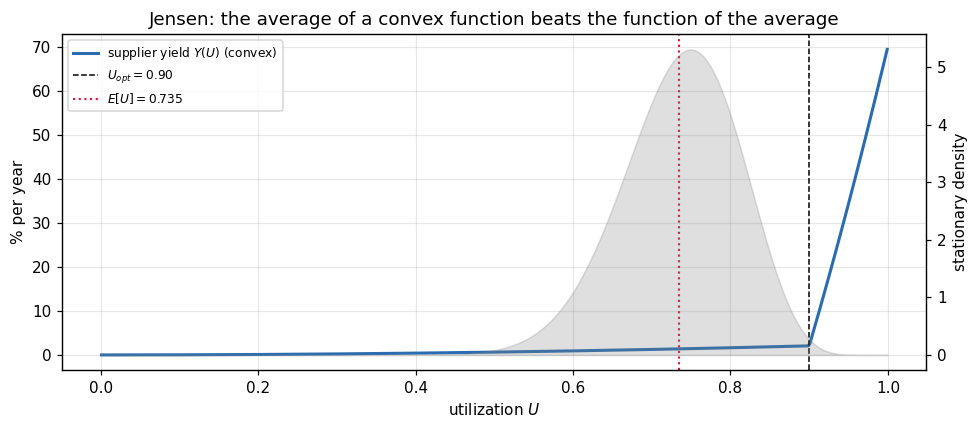

In [23]:
# --- Part XII: the supplier leg and the Jensen gap -----------------------
from optimal_long_short.barbell import barbell, keeper_leg, supplier_leg

rf_weth = float(configs.loc["WETH", "reserveFactor"])
jac_weth = fit_jacobi(u_weth, dt_years=1.0 / (365 * 24))
sl = supplier_leg(cv_weth, jac_weth, rf_weth)

print(f"WETH reserve, reserve factor {rf_weth}, Jacobi(kappa={jac_weth.kappa:.1f}, "
      f"theta={jac_weth.theta:.4f}, sigma={jac_weth.sigma:.3f})\n")
print(f"  E[Y(U)]  (integrate over the Beta law) : {100*sl.expected_yield:.4f}% / yr")
print(f"  Y(E[U])  (plug the average in)         : {100*sl.yield_at_mean:.4f}% / yr")
print(f"  Jensen gap = value of the kink         : {100*sl.jensen_gap:+.4f}% / yr"
      f"   ({100*sl.jensen_gap/sl.yield_at_mean:+.2f}% of the naive figure)")
print(f"  conditional yield  normal / stressed   : {100*sl.yield_normal:.3f}% / "
      f"{100*sl.yield_stressed:.3f}%   (ratio {sl.convexity_ratio:.2f}x)")
print("\nThe gap is positive by Jensen, and it is invisible to a deterministic-rate model.")

# picture of the convexity being priced
u_ax = np.linspace(0.001, 0.999, 500)
Y = np.array([(1 - rf_weth) * u * cv_weth.borrow_rate(u) for u in u_ax])
a_w = 2 * jac_weth.kappa * jac_weth.theta / jac_weth.sigma**2
b_w = 2 * jac_weth.kappa * (1 - jac_weth.theta) / jac_weth.sigma**2
fig, ax = plt.subplots()
ax.plot(u_ax, 100 * Y, lw=2, color="#2b6cb0", label=r"supplier yield $Y(U)$ (convex)")
ax.axvline(cv_weth.u_opt, color="k", ls="--", lw=1, label=fr"$U_{{opt}}={cv_weth.u_opt:.2f}$")
ax.axvline(sl_mean := float(_st.beta(a_w, b_w).mean()), color="crimson", ls=":", lw=1.4,
           label=fr"$E[U]={sl_mean:.3f}$")
ax2 = ax.twinx()
ax2.fill_between(u_ax, _st.beta(a_w, b_w).pdf(u_ax), color="grey", alpha=0.25)
ax2.set_ylabel("stationary density"); ax2.grid(False)
ax.set_xlabel("utilization $U$"); ax.set_ylabel("% per year")
ax.set_title("Jensen: the average of a convex function beats the function of the average")
ax.legend(fontsize=8, loc="upper left"); plt.tight_layout(); plt.show()

In [24]:
# --- Part XII: the keeper leg, and the barbell vs the levered book -------
h0_lev = 0.15
kl = keeper_leg(params, h0_lev, b=B, liq_bonus=lam_liq, T=T, close_factor=0.5, inverter=inv)
print(f"Keeper leg at h0 = {h0_lev} (the buffer the levered book chose):")
print(f"  debt per unit of borrower equity   = {kl['debt_per_equity']:.4f}")
print(f"  expected revenue over T = {T:.4f} yr = {kl['expected_revenue']:.5f}")
print("  (priced by the SAME transform (FP) that gave recovery in Part X)\n")

bb = barbell(params, curve=cv_weth, jacobi=jac_weth, reserve_factor=rf_weth,
             h0_levered=h0_lev, h0_safe=3.0, b=B, liq_bonus=lam_liq, T=T,
             w_keeper=0.10, close_factor=0.5, inverter=inv)
print(f"Barbell: {100*bb.w_safe:.0f}% safe supply + {100*bb.w_keeper:.0f}% keeper\n")
print(pd.DataFrame([
    {"strategy": "barbell", "mean payoff": bb.barbell_mean, "variance": np.nan,
     "p_liq": 0.0},
    {"strategy": f"levered book (h0={h0_lev})", "mean payoff": bb.levered_mean,
     "variance": bb.levered_var, "p_liq": bb.levered_p_liq},
]).to_string(index=False))
print(f"\nsafe-leg yield {100*bb.safe_yield:.4f}%/yr, of which "
      f"{100*bb.jensen_gap:.4f}%/yr is the kink premium")
print("The barbell carries no liquidation risk of its own and is long both convexities;")
print("the levered book is short both and pays negative carry for the privilege.")

Keeper leg at h0 = 0.15 (the buffer the levered book chose):
  debt per unit of borrower equity   = 2.0428
  expected revenue over T = 0.0833 yr = 0.00565
  (priced by the SAME transform (FP) that gave recovery in Part X)

Barbell: 90% safe supply + 10% keeper

              strategy  mean payoff  variance  p_liq
               barbell       0.9016       NaN 0.0000
levered book (h0=0.15)       0.9816    0.0522 0.0971

safe-leg yield 1.4220%/yr, of which 0.0457%/yr is the kink premium
The barbell carries no liquidation risk of its own and is long both convexities;
the levered book is short both and pays negative carry for the privilege.


---
# Part XIII. Addition #10 --- sizing on the map: when does leverage pay, and did it?

**What changed.** Paper §9 and `jobs/breakeven_drift.py`, `jobs/realised_backtest.py`. Parts IV
and X built the map from a buffer to the distribution of terminal wealth. This Part asks the
question a borrower actually has: **should I borrow at all?** The answer comes in four steps:

1. a closed-form **break-even drift** --- the relative drift above which a little leverage pays;
2. what the data say about that drift (almost nothing, for a reason worth understanding);
3. a **realised backtest** of all 37 pairs: did leverage pay, with no model at all;
4. what the backtest reveals about the model itself.

## XIII.1 Ask the question at the margin

Write $x=n_2S_{2,0}$ for the debt per dollar of equity, so the position holds $1+x$ dollars of
collateral, owes $x$ dollars of the second asset, and has leverage $L_0=1+x$. Unlevered is $x=0$.

Instead of searching over all $x$, ask a smaller question: **does the first cent of debt help?**
When $x$ is tiny the buffer $h_0$ is enormous, so liquidation cannot happen over a month, and
terminal wealth is simply

$$W_T=(1+x)\,e^{X_{1,T}}-x\,e^{X_{2,T}} .$$

Differentiate with respect to $x$ at $x=0$. For the **log-wealth (Kelly)** investor, using
$\frac{d}{dx}\log W=\frac{1}{W}\frac{dW}{dx}$ and $W=e^{X_{1,T}}$ at $x=0$:

$$\frac{d}{dx}\mathbb E[\log W_T]\Big|_{x=0}=\mathbb E\!\left[\frac{e^{X_{1,T}}-e^{X_{2,T}}}{e^{X_{1,T}}}\right]
=1-\mathbb E\bigl[e^{X_{2,T}-X_{1,T}}\bigr].$$

So the first cent of debt helps **exactly when $\mathbb E[e^{X_{2,T}-X_{1,T}}]<1$**. If the objective
is concave in $x$ --- and $\log$ of something linear in $x$ is concave --- that one sign decides
between "don't borrow" and "borrow something". (Liquidation breaks the concavity argument at large
$x$; the paper checks numerically that the switch still happens where this formula says.)

## XIII.2 Turning the condition into a number

$X_1$ and $X_2$ are a pair of Lévy processes, so $\mathbb E[e^{a_1X_{1,T}+a_2X_{2,T}}]=e^{T\Psi_{\mathrm M}(a_1,a_2)}$
with (Part II's exponent, read as a moment generating function)

$$\Psi_{\mathrm M}(a_1,a_2)=a_1\mu_1^X+a_2\mu_2^X+\tfrac12\bigl(a_1^2\sigma_1^2+a_2^2\sigma_2^2+2\rho a_1a_2\sigma_1\sigma_2\bigr)
+\lambda_1\bigl(M_1(a_1)-1\bigr)+\lambda_2\bigl(M_2(a_2)-1\bigr).$$

We need $(a_1,a_2)=(-1,1)$. Substitute the drift of §II.5, $\mu_i^X=\mu_i-\tfrac12\sigma_i^2-\lambda_i\bigl(M_i(1)-1\bigr)$,
and collect terms. The $\sigma_2^2$ and $M_2(1)$ pieces cancel in pairs, and $\mu_2$ survives only
inside the spread drift, leaving

$$\Psi_{\mathrm M}(-1,1)=-(\mu_1-\mu_2)+\sigma_1^2-\rho\sigma_1\sigma_2+\lambda_1\bigl[M_1(1)+M_1(-1)-2\bigr].$$

Setting it to zero gives the **Kelly break-even drift**, with $\nu:=\mu_1-\mu_2$ the spread drift
(price growth plus net carry):

$$\boxed{\;\nu^\star_{\mathrm{Kelly}}=\underbrace{\sigma_1^2-\rho\sigma_1\sigma_2}_{\text{diffusion}}
+\underbrace{\lambda_1\bigl[M_1(1)+M_1(-1)-2\bigr]}_{\text{collateral's own jumps}}\;}$$

Three things to notice.

* **$T$ has dropped out.** The break-even is the same for a week or a year.
* **The diffusion part is negative** when the collateral is the calmer leg ($\sigma_1<\rho\sigma_2$):
  shorting a more volatile, correlated asset *reduces* risk at the margin.
* **The jump part is positive**, because $M_1(1)+M_1(-1)-2=\mathbb E[e^{J}+e^{-J}-2]\ge0$. In this
  model the two legs jump *independently*, so the short leg cannot hedge the collateral's jumps.
  Remember this --- XIII.6 will show it is the model's weak point.

Leverage pays at the margin if and only if $\nu>\nu^\star$. For mean--variance the same argument
gives a break-even that is close to linear in $\alpha$.

In [25]:
# --- Part XIII: the break-even drift, by formula and by root-finding -------
from jobs.breakeven_drift import kelly_closed_form, breakeven

def M1(s):
    return params.p1 / (1 - s * params.eta1_pos) + (1 - params.p1) / (1 + s * params.eta1_neg)

diffusion = params.sigma1**2 - params.rho * params.sigma1 * params.sigma2
jumps = params.lam1 * (M1(1.0) + M1(-1.0) - 2.0)
print(f"sigma1 = {params.sigma1:.3f}  <  rho*sigma2 = {params.rho * params.sigma2:.3f}"
      f"  ->  diffusion part {diffusion:+.4f}")
print(f"WBTC jump part  lambda1*[M1(1)+M1(-1)-2] = {jumps:+.4f}")
print(f"Kelly break-even (by hand)                 = {diffusion + jumps:+.4f}")
print(f"Kelly break-even (package closed form)     = {kelly_closed_form(params)['nu_star']:+.4f}")

BE = json.load(open(ROOT / "results/breakeven_drift.json"))
mu2_sample = BE["drift_estimates"]["headline_4h"]["mu2"]
print(f"Kelly break-even (root of 1-E[e^(X2-X1)])  = {breakeven(params, 'kelly', mu2_sample):+.4f}\n")

tab = pd.DataFrame({name: c["nu_star"] for name, c in BE["calibrations"].items()}).T
tab.columns = [f"alpha={k}" if k != "kelly" else "Kelly" for k in tab.columns]
print("break-even drifts nu* (per year) under three calibrations (paper Table 7):")
tab.round(3)

sigma1 = 0.264  <  rho*sigma2 = 0.278  ->  diffusion part -0.0037
WBTC jump part  lambda1*[M1(1)+M1(-1)-2] = +0.0116
Kelly break-even (by hand)                 = +0.0079
Kelly break-even (package closed form)     = +0.0079
Kelly break-even (root of 1-E[e^(X2-X1)])  = +0.0079

break-even drifts nu* (per year) under three calibrations (paper Table 7):


,alpha=0.5,alpha=1.0,alpha=2.0,Kelly
headline_4h,0.0040,0.0080,0.0160,0.0080
daily_full,0.0270,0.0540,0.1100,0.0480
4h_2024,0.0240,0.0490,0.0990,0.0450


The break-evens are **small**: under one percent a year at the headline calibration, a few percent
under the full-history ones. With no view at all, the drift is just the net carry, about
$-2.5\%$ a year for WBTC/WETH --- below every break-even, so the default is not to borrow. But a
modest belief that WBTC will outperform WETH is enough to justify some leverage. Everything now
hangs on one number: the spread drift $\nu$.

## XIII.3 What the data can say about a drift

This is a classical fact worth seeing explicitly. Estimate a drift $\mu$ from $n$ observations
over a window of length $\mathcal T$ years. The estimator is $\widehat\mu=X_{\mathcal T}/\mathcal T$, with

$$\operatorname{sd}(\widehat\mu)=\frac{\sigma\sqrt{\mathcal T}}{\mathcal T}=\frac{\sigma}{\sqrt{\mathcal T}} .$$

**The sampling frequency $n$ does not appear.** Only the *calendar length* matters. Sampling every
four hours instead of every day gives six times the data and *exactly the same* precision on the
drift. Volatility is the opposite: $\operatorname{sd}(\widehat\sigma^2)\propto\sigma^2\sqrt{2/n}$,
which shrinks as you sample faster. High-frequency data give sharp volatilities and hopeless drifts.

Two practical consequences.

* The calibration's $\mu_i$ are **not drift estimates**. The ECF is fitted to returns with their
  moving average removed, so $\mu_i$ only normalise the fit; their difference, $-0.86$, even has the
  opposite sign to the window's realised drift. The drift has to come from sample means:
  $\nu=\nu_{\mathrm{price}}+c$, with the carry $c=r_s-r_b$ read off the protocol.
* Over $3.7$ years the standard error of $\nu$ is about $0.19$ a year. To tell a drift of $+0.10$
  from a break-even of $+0.05$ at two standard errors needs a standard error of $0.025$, i.e.
  $3.7\times(0.19/0.025)^2\approx210$ years of data.

In [26]:
# --- Part XIII: the sample drift and how uncertain it is -------------------
D = pd.DataFrame(BE["drift_estimates"]).T[["nu_price", "carry", "nu", "se_nw"]]
print("sample spread drift (per year): price growth + carry, Newey-West standard error")
print(D.round(3).to_string(), "\n")
se_needed = (0.10 - 0.05) / 2
years_needed = 3.7 * (D.loc["full_history", "se_nw"] / se_needed) ** 2
print(f"years of data needed to separate +0.10 from +0.05 at 2 s.e.: {years_needed:.0f}")

sample spread drift (per year): price growth + carry, Newey-West standard error
              nu_price   carry     nu  se_nw
headline_4h     0.1280 -0.0250 0.1030 0.3360
full_history    0.1260 -0.0270 0.0990 0.1880 

years of data needed to separate +0.10 from +0.05 at 2 s.e.: 210


## XIII.4 A probability instead of a leverage number

If the drift cannot be pinned down, put a distribution on it. Take a prior centred on the carry,
$\nu\sim\mathcal N(c,0.20^2)$ --- "relative prices have no predictable drift" --- and update with the
sample estimate. The posterior is normal, $\mathcal N(m,s^2)$, and $\mathbb P(\nu>\nu^\star)$ is the
probability that leverage pays.

The Kelly investor who averages over the posterior (**Bayes--Kelly**) has an exact rule at the
margin. In the model $\mathbb E[e^{X_{2,T}-X_{1,T}}]=e^{T(\nu^\star-\nu)}$, so the averaged
derivative is $1-e^{T\nu^\star}\mathbb E_{\mathrm{post}}[e^{-T\nu}]=1-e^{T(\nu^\star-m)+\frac12T^2s^2}$,
using the normal moment generating function. It is positive iff

$$m>\nu^\star_{\mathrm{Kelly}}+\tfrac12\,T s^2 .$$

The correction $\tfrac12Ts^2$ is tiny (about $0.001$), so the decision is made by the **posterior
mean** --- that is, by how hard the prior pulls the sample drift toward zero.

In [27]:
# --- Part XIII: posteriors and the Bayes-Kelly rule ------------------------
rows = []
for name, c in BE["calibrations"].items():
    rule = c["bayes_kelly_closed_rule"]
    rows.append({"calibration": name,
                 "P(lever pays) carry prior": c["P_leverage_pays"]["kelly"],
                 "P(lever pays) flat prior": c["P_leverage_pays_flat_prior"]["kelly"],
                 "posterior mean m": rule["posterior_mean"],
                 "threshold nu* + T s^2/2": rule["threshold_on_posterior_mean"],
                 "Bayes-Kelly levers?": rule["levers"]})
print(pd.DataFrame(rows).set_index("calibration").round(3).to_string())
print("\nUnder the carry prior the posterior mean sits just below the threshold, so Bayes-Kelly")
print("stays unlevered; under a flat prior m = nu_hat ~ 0.10 and it levers. The choice is the prior's.")

             P(lever pays) carry prior  P(lever pays) flat prior  posterior mean m  threshold nu* + T s^2/2  Bayes-Kelly levers?
calibration                                                                                                                     
headline_4h                     0.5010                    0.6110            0.0080                   0.0090                False
daily_full                      0.4740                    0.6050            0.0390                   0.0490                False
4h_2024                         0.4830                    0.6110            0.0390                   0.0460                False

Under the carry prior the posterior mean sits just below the threshold, so Bayes-Kelly
stays unlevered; under a flat prior m = nu_hat ~ 0.10 and it levers. The choice is the prior's.


## XIII.5 Did leverage pay? A realised backtest

Everything so far is model-based. The cleanest check needs no model: take the real history and
replay the position. `jobs/realised_backtest.py` does this for **all 37 pairs** of Part VII, hour by
hour, from January 2023 to October 2026:

* equity starts at \$1; the book is set to leverage $L_0$ and reset every 1, 7, 30, 90 or 365 days,
  or simply held;
* each hour the collateral earns its supply rate and the debt accrues its borrow rate;
* whenever the health factor is below one, a keeper repays half the debt (all of it if
  $H\le0.95$) and takes collateral worth the repayment plus the bonus --- Aave's actual rule;
* the benchmark holds the collateral unlevered.

The quantity reported is the **excess log growth** per year of the levered book over the
unlevered one.

median excess log growth per year across the 37 pairs (paper Table 8):
L0         1.25     1.5     2.0     3.0
horizon                                
1       -0.0380 -0.1020 -0.2870 -0.7680
30      -0.0420 -0.1130 -0.3310 -0.9940
365     -0.0080 -0.1120 -0.5590 -0.8890
hold    -0.0170 -0.0360 -0.3030 -0.4510

number of pairs (of 37) in which leverage beat the unlevered book:
L0       1.25  1.5  2.0  3.0
horizon                     
1           4    4    3    0
30          4    4    4    1
365         5    5    3    2
hold       12   12   10    7


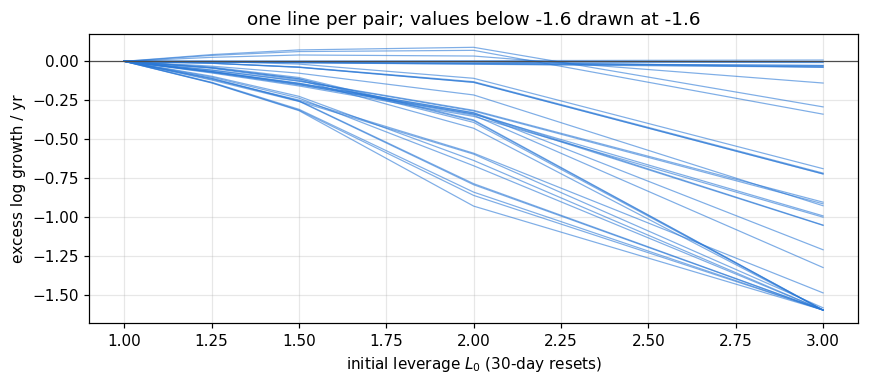

In [28]:
# --- Part XIII: the realised backtest ---------------------------------------
RB = pd.read_csv(ROOT / "results/realised_backtest_pairs.csv")
RB["horizon"] = RB.horizon.astype(str); RB["L0"] = RB.L0.astype(str)
base = RB[(RB["mode"] == "aave") & (RB.cost_bps == 0)]
order, cols = ["1", "30", "365", "hold"], ["1.25", "1.5", "2.0", "3.0"]
med = base.pivot_table(index="horizon", columns="L0", values="excess", aggfunc="median").loc[order, cols]
won = base.assign(w=base.excess > 0).pivot_table(index="horizon", columns="L0", values="w",
                                                aggfunc="sum").loc[order, cols].astype(int)
print("median excess log growth per year across the 37 pairs (paper Table 8):")
print(med.round(3).to_string())
print("\nnumber of pairs (of 37) in which leverage beat the unlevered book:")
print(won.to_string())

fig, ax = plt.subplots(figsize=(8, 3.6))
for (c, d), g in base[base.horizon == "30"].groupby(["collateral", "debt"]):
    g = g[g.L0.isin(cols)].assign(L=lambda z: z.L0.astype(float)).sort_values("L")
    ax.plot([1.0] + list(g.L), [0.0] + list(g.excess.clip(lower=-1.6)), color="#2a78d6", lw=0.8, alpha=0.6)
ax.axhline(0, color="0.3", lw=0.8)
ax.set_xlabel("initial leverage $L_0$ (30-day resets)")
ax.set_ylabel("excess log growth / yr")
ax.set_title("one line per pair; values below -1.6 drawn at -1.6")
plt.tight_layout(); plt.show()

Leverage **rarely paid**. At a modest $1.25\times$ it beat the unlevered book in 4 of 37 pairs ---
all of them long BTC, in a window where BTC rose 3.6-fold and more than doubled against ETH ---
and in none of them by a statistically significant margin. Higher leverage loses through
**volatility drag** (against a dollar debt, re-levering costs about $\tfrac12\sigma^2(L^2-1)$ a year) and,
for books left a week or more, through **liquidations**. Resetting more often does not help.

Is it "profitable in the short run"? Only in the sense of *some calendar years*:

In [29]:
# --- Part XIII: by calendar year -------------------------------------------
RBJ = json.load(open(ROOT / "results/realised_backtest.json"))
years = pd.DataFrame({f"{q['collateral']}/{q['debt']}": {y: v["excess"] for y, v in q["by_year_L2_30d"].items()}
                      for q in RBJ["pairs"] if q["group"] == "cross-asset"}).T
print("cross-asset books at 2x, 30-day resets -- share of pairs with positive excess growth:")
for y in years:
    s = years[y].dropna()
    print(f"  {y}: {(s > 0).sum():2d} of {len(s)}")
print("\n2023-26 is one cycle: a bull market to the 2025 peaks, then BTC -53% and ETH -68% to mid-2026.")

cross-asset books at 2x, 30-day resets -- share of pairs with positive excess growth:
  2023:  7 of 13
  2024:  8 of 29
  2025:  0 of 29
  2026:  2 of 29

2023-26 is one cycle: a bull market to the 2025 peaks, then BTC -53% and ETH -68% to mid-2026.


## XIII.6 What the backtest says about the model

The backtest also gives a **model-free break-even**. Repeat XIII.1 with real daily returns
$R_1,R_2$ (gross, interest included): a little daily-reset leverage pays iff
$\mathbb E[R_2/R_1]<1$. The realised analogue of $\nu^\star$ is collateral variance minus covariance,
$\widehat{\nu}^\star\approx\widehat{\mathrm{Var}}(X_1)-\widehat{\mathrm{Cov}}(X_1,X_2)$ per year.

For WBTC/WETH the model says $\nu^\star=+0.048$ (full-history fit). The data say:

In [30]:
# --- Part XIII: model versus realised second moments, WBTC/WETH ------------
from jobs.realised_backtest import load_pair

full = json.load(open(ROOT / "results/horizon_analysis.json"))["calibrations"]["daily_full"]

def moments(var1, var2, cov):
    return {"var WBTC": var1, "var WETH": var2, "cov": cov, "corr": cov / math.sqrt(var1 * var2),
            "spread var": var1 + var2 - 2 * cov, "nu* = var1 - cov": var1 - cov}

def kou_var(sig, lam, p, up, dn):        # E[J^2] = 2*eta^2 for an exponential of mean eta
    return sig**2 + lam * (p * 2 * up**2 + (1 - p) * 2 * dn**2)

model = moments(kou_var(full["sigma1"], full["lam1"], full["p1"], full["eta1_pos"], full["eta1_neg"]),
                kou_var(full["sigma2"], full["lam2"], full["p2"], full["eta2_pos"], full["eta2_neg"]),
                full["rho"] * full["sigma1"] * full["sigma2"])
d = np.log(load_pair("WBTC", "WETH")[["S1", "S2"]].resample("1D").last()).diff().dropna()
real = moments(d.S1.var() * 365, d.S2.var() * 365, d.cov().iloc[0, 1] * 365)
print(pd.DataFrame({"model (independent jumps)": model, "realised, daily": real}).round(3).to_string())

big = d[(d.abs() > 3 * d.std()).any(axis=1)]
same = ((np.sign(big.S1) == np.sign(big.S2)) & (big.abs() > 1.5 * d.std()).all(axis=1)).mean()
print(f"\nlarge days (3 s.d. in either leg): {len(big)};  both legs moved > 1.5 s.d. the same way on {same:.0%}")

                  model (independent jumps)  realised, daily
var WBTC                             0.1540           0.2130
var WETH                             0.2850           0.4000
cov                                  0.1060           0.2360
corr                                 0.5040           0.8080
spread var                           0.2280           0.1410
nu* = var1 - cov                     0.0480          -0.0230

large days (3 s.d. in either leg): 34;  both legs moved > 1.5 s.d. the same way on 85%


The realised break-even is **negative**, the model's positive. The reason is the boxed formula's
second term. In the data, the big moves are **common**: on most days when one leg jumps, so does the
other. The model's two jump processes are independent, so the only channel for co-movement is the
Brownian correlation $\rho$. The fit cannot match the common jumps; it understates both variances
and, by much more, the covariance. Two consequences:

* the **spread variance is overstated** by about 60%, which pushes the model's liquidation
  probabilities above realised frequencies (paper Appendix C);
* the **break-even turns positive**, so the model says leverage needs a positive view when, on this
  history, it paid at any non-negative drift.

The fix is a **common jump component**: a third Poisson process that moves both legs at once. With
double-exponential marks the spread's jumps stay in the mixed-exponential class of Part III, at the
cost of more phases and a larger barrier system. It is the most consequential extension of the
model.

## XIII.7 The conclusion, stated plainly

> The map is exact and fast *given its inputs*. The input that decides whether to borrow --- the
> relative drift --- cannot be estimated; ex post, leverage rarely paid; and the model's
> independent jumps bias both its break-even and its liquidation probabilities.

So the paper **does not report an optimal buffer**. It reports what the map is good for:
evaluating a buffer under a stated view or a stress scenario. This is the payoff of Addition #1:
because the map and the decision rule were separated from the start, the paper can say exactly
which output depends on which input.

---
# Part XIV. Everything in one place

## XIV.1 The additions, and what each one costs

| # | Addition | New mathematics needed | Cost |
|---|---|---|---|
| 1 | Evaluation map | none --- a reorganisation | free |
| 2 | Aave data layer | none | one fetcher |
| 3 | Carry as a drift | one substitution $\mu_i\mapsto\mu_i+r_i$ | one line |
| 4 | Screen + cross-section | the ratio $\mathrm{CB}=cT/(\sigma_Z\sqrt T)$ | one pass over the panel |
| 5 | Depeg overlay | $h_0\mapsto h_0+\log(1-d)$ | re-evaluate the map |
| 6 | Rate curve + Jacobi | invert a piecewise-linear map; a bounded diffusion | a regression |
| 7 | Recovery $R_\tau$ | Esscher tilt + the transform (FP); bivariate tilt for exact overshoot | one extra inversion per hitting moment |
| 8 | Regime switching | degree-12 characteristic equation, $6\times6$ barrier system | genuinely new |
| 9 | Barbell | Jensen + the *same* (FP) transform | reuses #6 and #7 |
| 10 | Sizing on the map | one first-order condition, closed form for Kelly; a model-free replay | it costs the headline result |

The pattern worth noticing: **nine of the ten additions cost little new mathematics**, because the base
framework was built around objects (a drift, a buffer, a first-passage transform, a barrier
system) that generalise. Only #8 needed new derivations, and even there the enlargement was
mechanical --- everything doubled and the boundary conditions still counted correctly.

## XIV.2 The findings, in order of how uncomfortable they are

1. Carry is free to model (Part VI) --- **and inert** on every volatile pair (Part VII).
2. The leveraged long-crypto book **pays** $1.8\%$--$4.5\%$ carry rather than earning it, while
   being short two convexities (Parts VII, XII).
3. The old CIR rate fits were not merely badly estimated; they were **structurally the wrong
   object** (Part IX).
4. The reported utilization series is **biased**, overstating stress by $2.4\times$ for USDC
   (Part IX).
5. The killed-payoff convention **overstates risk substantially**: recovery cuts the variance
   of terminal wealth by more than half near the barrier; exact overshoot takes back only a
   few percent of that at the fitted jump sizes (Part X).
6. What matters about the rate is its **tail, not its mean** --- and calibrated, even the tail is
   small at a monthly horizon: the opening regime moves survival by at most $0.09$ pp (Part XI).
7. Whether to borrow turns on a **break-even drift** of a few percent a year, and the drift
   cannot be estimated well enough to say whether it is exceeded: the posterior gives leverage
   about an even chance (Part XIII).
8. **Ex post, leverage rarely paid**: replayed under Aave's rules, $1.25\times$ beat the unlevered
   book in 4 of 37 pairs, never significantly (Part XIII).
9. The model's **independent jumps** understate the legs' covariance, overstate spread variance and
   flip the sign of the WBTC/WETH break-even; common jumps are the fix (Part XIII).

## XIV.3 Source map --- where to look for each thing

| Topic | Module | Job / entry point | Paper |
|---|---|---|---|
| Model parameters, compensator | `model_params.py` | --- | §3 |
| Roots, resolvent, moments | `root_finder.py`, `laplace_resolvent.py`, `moments.py` | `tests/test_core_resolvent.py` | §4--5, App. A |
| Laplace inversion | `inversion.py` | `mc_convergence.py` | §5, §6.1 |
| Evaluation map | `risk_report.py` | `h0_liquidation_report.py` | §2.2 |
| Aave data | `aave_hourly.py` | `fetch_universe.py`, `build_merged_4h.py` | App. B--C |
| Calibration, benchmark drift | `calibration/` (penalised ECF) | `calibrate_btc_eth.py --merged`, `build_benchmark_params.py`, `bootstrap_se.py` | §6, App. B |
| Screen, cross-section | `screen.py` | --- | App. D.2 |
| Rate curve, utilization, Jacobi | `rate_curve.py` | --- | App. D.3 |
| Carry, depeg, target-$p_{\rm liq}$ | `carry.py` | `carry_frontier.py` | App. D.1, D.4 |
| Recovery (continuous / exact) | `recovery.py`, `overshoot_recovery.py` | `validate_recovery.py`, `overshoot_table.py` | §7 |
| Regime switching | `regime_switching.py` | `validate_regime_switching.py`, `regime_calibration.py` | App. D.3, D.5 |
| Barbell | `barbell.py` | --- | --- |
| Expected log wealth, overshoot law | `kelly.py` | `kelly_sizing.py` | §7.4--7.5 |
| Decision rules, fractional Kelly | `moments.py` | `decision_rules.py` | §8.1 |
| Break-even drift, posteriors, Bayes--Kelly | `drift.py`, `kelly.py` | `breakeven_drift.py` | §8.2--8.3 |
| Full history, out-of-sample backtest | `full_history.py` | `horizon_analysis.py`, `rolling_backtest.py`, `backtest_bias.py` | App. C |
| Realised 37-pair backtest | --- | `realised_backtest.py`, `fig_realised_backtest.py` | §8.4 |

Data lives in `data/AAVE/` (twelve `hourly_*.parquet` files, `reserve_configs_v3_eth.csv`, and
the headline panel `merged_wbtc_weth_4h.parquet`) and `data/AAVE_full/` (the full 2023--2026
history); outputs in `results/` (`params_WBTC_WETH.json`, `pair_cross_section.csv`,
`bootstrap_se.json`, `breakeven_drift.json`, `realised_backtest.json`, `horizon_analysis.json`,
`rolling_backtest.json`, `regime_calibrated.json`, `model_comparison.json`).

## XIV.4 Glossary --- every symbol used in this notebook

| Symbol | Name | Where defined |
|---|---|---|
| $S_{i,t}$, $n_i$, $V_{i,t}$ | price, holding, leg value | §I.2 |
| $b$ | liquidation threshold (collateral haircut) | §I.3 |
| $\mathrm{LTV}_{\max}$ | origination loan-to-value cap | §I.5 |
| $H_t$, $h_t=\log H_t$ | health factor and log health | §I.3 |
| $h_0$, $h_0^{\min}$ | initial buffer, and its contractual floor | §I.4--I.5 |
| $L_0=H_0/(H_0-b)$ | initial gross leverage | §I.5 |
| $\tau$ | liquidation (first-passage) time | §I.3 |
| $X_{i,t}$ | cumulative log-return of asset $i$ | §I.4 |
| $Z_t=X_{1,t}-X_{2,t}$ | log price ratio --- the only state variable | §I.4 |
| $\sigma_Z$ | annualised volatility of $Z$ | §II.7 |
| $\mu_i$ | expected **price** growth rate | §II.5 |
| $\mu_i^X$ | **log-price** drift, $=\mu_i-\tfrac12\sigma_i^2-\lambda_i\chi_i$ | §II.5 |
| $\sigma_i$, $\rho$ | diffusion volatility; Brownian correlation | §II.2, §II.7 |
| $\lambda_i$ | jump intensity (jumps per year) | §II.3 |
| $p_i$ | probability a jump is upward | §II.4 |
| $\eta_{i,\pm}$ | mean up/down jump size; needs $\eta_{i,+}<1$ | §II.4--II.5 |
| $\chi_i=\mathbb E[e^{J_i}-1]$ | jump compensator | §II.5 |
| $\Psi$, $\psi_Z$ | Lévy exponent (pair; and of $Z$) | §II.6--II.7 |
| $r_{1,-},r_{2,-}$ | downward exponential phase rates of $Z$ | §II.7 |
| $T$ | horizon (years) | §III.1 |
| $\Pi_T$ | killed payoff | §III.1 |
| $\mathbf 1_{\{A\}}$ | indicator of event $A$ | §III.1 |
| $M_k=\mathbb E[\Pi_T^k]$ | killed moment of order $k$ | §III.3 |
| $p_{\mathrm{surv}}$, $p_{\mathrm{liq}}$ | survival / liquidation probability | §III.3 |
| $q$ | Laplace variable | §III.4 |
| $\gamma$ | characteristic root | §III.5 |
| $\alpha$, $\delta$ | risk aversion; liquidation penalty | §IV.2 |
| $\Phi$ | penalised mean--variance objective | §IV.2 |
| $r_s$, $r_b$ | supply APR (earned), borrow APR (paid) | §VI.1 |
| $c=r_s-r_b$ | net carry | §VI.2 |
| $\mathrm{CB}=cT/(\sigma_Z\sqrt T)$ | carry-to-barrier ratio | §VII.2 |
| $d$ | collateral depeg fraction | §VIII.2 |
| $U$, $U_{\mathrm{opt}}$ | utilization; the kink | §IX.1 |
| $r_0,s_1,s_2$ | rate-curve base and two slopes | §IX.1 |
| rf | reserve factor (protocol's cut) | §IX.1 |
| $\kappa,\theta,\sigma$ | Jacobi mean-reversion speed, level, vol | §IX.4 |
| $a,b$ (Beta) | stationary shape parameters $2\kappa\theta/\sigma^2$, $2\kappa(1-\theta)/\sigma^2$ | §IX.4 |
| $\lambda$ (bonus) | liquidation bonus --- **not** the jump intensity | §X.2 |
| $R_\tau$, $W_T$ | recovery at liquidation; terminal wealth | §X.1--X.2 |
| $\alpha_k=\Psi(0,-ik)$ | tilt exponent | §X.4 |
| $\mathbb P^{(k)}$ | Esscher-tilted measure | §X.4 |
| $J_t$, $Q$, $q_1,q_2$ | regime, generator, switching rates | §XI.2 |
| $\pi_1,\pi_2$ | stationary regime probabilities | §XI.2 |
| $c_1,c_2$ | net carry per regime | §XI.3 |
| $\psi^i$, $A(\gamma)$, $\Delta(\gamma)$ | per-regime exponent, kernel matrix, characteristic function | §XI.3--XI.5 |
| $\mathbf M_{\mathrm{bar}}$ | the $6\times6$ barrier matrix | §XI.6 |
| $Y(U)$ | supplier yield | §XII.3 |
| $x$ | debt per dollar of equity, $L_0=1+x$ | §XIII.1 |
| $\nu=\mu_1-\mu_2$ | spread drift (price growth plus net carry) | §XIII.2 |
| $\Psi_{\mathrm M}(a_1,a_2)$ | joint log moment generating function of $(X_1,X_2)$ | §XIII.2 |
| $\nu^\star$ | break-even drift: leverage pays at the margin iff $\nu>\nu^\star$ | §XIII.2 |
| $m,s$ | posterior mean and standard deviation of $\nu$ | §XIII.4 |
| $R_1,R_2$ | realised daily gross returns, interest included | §XIII.6 |

## XIV.5 What is still open

* **Common jumps.** The two legs jump independently in the model, but not in the data (Part
  XIII.6). A common Poisson component is the most consequential extension.
* The liquidation bonus is exogenous; in the overshoot regime, market impact would make it
  endogenous.
* The regime is **exogenous**: utilization drives the carry but nothing drives utilization.
  Endogenising it would let stress and price moves co-move, which is what actually happens.
* Depegs and the rate regime are modelled separately, though the same deleveraging causes both.
* The framework still abstracts from oracle delays, liquidation execution, market impact, and
  dynamic collateral management.

## XIV.6 If you remember three things

1. **The whole problem is one scalar first-passage problem**, $h_t=h_0+Z_t$. Everything else is
   machinery for evaluating it fast, or an economic feature folded into $Z$'s drift.
2. **Adding a feature is cheap when it enters as a drift or a shifted buffer** (carry, depeg,
   regime carry) and expensive only when it changes the *structure* of the equation
   (regime switching, which doubled the system).
3. **Separate what the model computes from what you decide with it.** That separation is the
   only reason Part XIII can say precisely what the data do and do not support.